<div align="center">

# Proyecto Integrador de Ciencia de Datos
## Fase 1 (actividades 1 y 2) · Cuaderno de soporte del informe

### ¿Cuál es la energía renovable con mejor desempeño integral?
#### Un análisis de 24 794 plantas renovables de 150 países con la *Global Power Plant Database* (WRI)

**Carolina Rodríguez Chacón** · carodriguez03@unisalle.edu.co<br>
Maestría en Inteligencia Artificial · Facultad de Ingeniería · **Universidad de La Salle**<br>
**Curso:** 2026-2_Ciencia de Datos_G2 · **Docente:** Fabián Camilo Castro Riveros<br>
**Actividades del aula:** Fase 1, actividades 1 y 2 – Conformación del equipo, selección del dataset, planteamiento del problema, objetivos y análisis exploratorio (Entregable 1, 20 %)<br>
**Cierre en el aula:** Actividad 1, 25 de octubre; Actividad 2, 1 de noviembre de 2026 · **Fecha de elaboración:** octubre de 2026

</div>

---

### Qué es este cuaderno

Este cuaderno acompaña al informe de la Fase 1 (actividades 1 y 2) y **reproduce todas sus tablas y figuras**: cada una se genera en la sección que indica la tabla siguiente, con el mismo número que tiene en el informe. Se limita a la Fase 1 (planteamiento del problema y análisis exploratorio); la limpieza definitiva, el modelado y el tablero corresponden a las fases 2 a 4.

Es reproducible: si los archivos de datos no están en la carpeta `data/raw/`, los descarga de sus repositorios oficiales (funciona igual en Google Colab y en Jupyter local). Cada bloque de código va precedido de una explicación y seguido de su interpretación.

| Informe | Contenido | Sección del cuaderno |
|---|---|---|
| Sección III y Tabla II | Equipo, criterios de selección y fuentes candidatas (Actividad 1) | 1 |
| Sección II y Tabla I | Contexto, impacto, preguntas y objetivos SMART | 2 |
| Tablas III, IV y V | Ficha técnica, diccionario de las 36 columnas y variables derivadas | 3 |
| Tabla VI | Indicadores de calidad: faltantes, incoherencias y duplicados | 4.2 y 5.1–5.4 |
| Tabla VII | Valores atípicos con la regla IQR y el Z-score | 5.5 |
| Tablas VIII y X | Estadísticos descriptivos, generales y por tecnología | 6.1 |
| Tabla IX | Frecuencias de las variables cualitativas | 6.2 |
| Figuras 1 y 2 | Rendimiento y estabilidad por tecnología; mapa rendimiento–estabilidad | 7.1 |
| Figura 3 | Matrices de correlación de Pearson y Spearman | 7.2 |
| Figura 4 | Efectos de la ubicación y la antigüedad según la tecnología | 7.3 |
| Tabla XI | Pruebas χ² de independencia | 7.4 |
| Tabla XII | Índice exploratorio de desempeño integral | 8 |
| Tabla XIII | Prueba de concepto frente a las metas SMART | 9 |
| Tablas XIV y XV | Las ocho categorías de Enel; energía marina por tipo | 10.2 y 10.3 |
| Sección VI (Discusión) | Rendimiento de la solar, la eólica y la geotérmica por país | 10.5 |
| Secciones VI y VII | Hallazgos, limitaciones y referencias | 11–13 |

# 1. Actividad 1: conformación del equipo y selección del dataset

## 1.1 Conformación del equipo

Las reglas del curso permiten trabajar de forma individual o en grupos de hasta tres personas. Este proyecto se desarrolla de forma **individual**:

| Integrante | Rol | Responsabilidades |
|---|---|---|
| Carolina Rodríguez Chacón | Responsable del proyecto (trabajo individual) | Planteamiento del problema, obtención y preparación de los datos, análisis exploratorio, modelado, visualización, tablero y comunicación de resultados |

**Herramientas:** Python (pandas, NumPy, SciPy, statsmodels, scikit-learn, matplotlib y seaborn) en Jupyter y Google Colab. En las fases siguientes se añadirán PyTorch (perceptrón multicapa), Streamlit (tablero interactivo) y GitHub (repositorio público).

## 1.2 Criterios de selección

Se definieron ocho criterios. Los cinco primeros provienen de la guía del curso; los otros tres, del tema elegido (¿qué energía renovable tiene el mejor desempeño integral?):

| Criterio | Origen | Qué exige |
|---|---|---|
| C1. Acceso público | Guía §2 | Datos de acceso libre, con licencia explícita |
| C2. Repositorio permitido | Guía §2.1 | Kaggle, UCI, Google Dataset Search, Zenodo / IEEE DataPort o un portal oficial de datos abiertos |
| C3. ≥ 600 registros | Guía §2.2 | Al menos 600 filas de datos limpios |
| C4. ≥ 5 variables mixtas | Guía §2.2 | Variables cuantitativas (continuas o discretas) y cualitativas (nominales u ordinales) |
| C5. Versatilidad | Guía §2.2 | Una variable continua para regresión, una categórica para clasificación y varias cuantitativas para clustering |
| C6. Varias tecnologías | Tema | Cubrir varias fuentes renovables para poder compararlas |
| C7. Generación y capacidad | Tema | Tener ambas para medir la eficiencia (factor de planta) |
| C8. Detalle por planta | Tema | Una fila por planta, para explicar por qué unas plantas rinden más que otras |

## 1.3 Comparación de fuentes candidatas (Tabla II del informe)

Se compararon cuatro fuentes públicas reconocidas:

| Criterio | **GPPD** (WRI) | IRENASTAT (IRENA) | Energy dataset (Our World in Data) | Global Integrated Power Tracker (Global Energy Monitor) |
|---|---|---|---|---|
| Unidad de análisis | Planta | País × tecnología × año | País × año | Unidad de generación |
| C1. Acceso público | Sí | Sí | Sí | Sí |
| C2. Repositorio permitido | Sí (Google Dataset Search) | Sí (portal oficial) | No (GitHub) | No (sitio propio) |
| C3. ≥ 600 registros | Sí | Sí | Sí | Sí |
| C4. ≥ 5 variables mixtas | Sí (36) | Pocas | Sí | Sí |
| C5. Versatilidad | Sí | Parcial | Parcial | Parcial |
| C6. Varias tecnologías | Sí (6) | Sí | Sí | Sí |
| C7. Generación y capacidad | Sí | Solo agregadas | Solo agregadas | No (sin generación) |
| C8. Detalle por planta | Sí | No | No | Sí |
| **Cumple los 8** | **Sí** | No | No | No |

**Decisión.** Se selecciona la **Global Power Plant Database (GPPD) v1.3.0** del World Resources Institute, la única fuente que cumple los ocho criterios. IRENASTAT y Our World in Data permiten comparar tecnologías, pero solo con agregados por país, lo que impide explicar diferencias entre plantas. El tracker de Global Energy Monitor tiene detalle por unidad, pero sin generación no permite medir la eficiencia. IRENASTAT se conserva como **fuente complementaria**: en la sección 10 se usa para contrastar los resultados y para cubrir la energía marina y el almacenamiento.

La ficha técnica completa del dataset elegido está en la sección 3.

# 2. Planteamiento del problema

## 2.1 Contexto y dominio del problema

La generación de electricidad es una de las mayores fuentes de emisiones de CO₂ del mundo, y la transición hacia fuentes renovables es la principal palanca para reducirlas. En la COP28 (Dubái, 2023) los países acordaron **triplicar la capacidad renovable mundial a 2030**. Esa meta obliga a gobiernos, empresas y centros de investigación a decidir **en qué tecnologías concentrar inversión, investigación y políticas públicas**. Para un país como Colombia, cuya matriz eléctrica depende en gran parte de la hidroelectricidad y es vulnerable a las sequías asociadas al fenómeno de El Niño, la pregunta de *qué renovable conviene más* tiene consecuencias directas sobre la seguridad energética.

**¿Existen "más de 100" energías renovables?** Es frecuente leer esa cifra, pero corresponde a **variantes tecnológicas**, no a fuentes distintas. A escala de planta conectada a la red, prácticamente toda la capacidad renovable del mundo se agrupa en **seis familias de fuentes primarias**.

El *Learning Hub* de Enel ([enel.com/learning-hub/renewables](https://www.enel.com/learning-hub/renewables)) usa la misma clasificación y añade dos categorías complementarias:
- **Hidrógeno**, que Enel describe como un *vector energético* ("energy carrier"): se produce con electricidad renovable y sirve para almacenarla.
- **Almacenamiento**, que guarda la energía renovable pero no la genera.

Ninguna de las dos es una fuente primaria. La tabla muestra la correspondencia con el dataset elegido, que contiene las seis fuentes primarias:

| Clasificación del Enel Learning Hub | Familia en el dataset (`primary_fuel`) | Subtecnologías principales |
|---|---|---|
| Energía solar | Solar (`Solar`) | Fotovoltaica (silicio mono/policristalino, película delgada, bifacial, con seguimiento), termosolar de concentración (cilindro-parabólica, torre central) |
| Energía eólica | Eólica (`Wind`) | Terrestre, marina fija, marina flotante |
| Energía hidroeléctrica | Hidroeléctrica (`Hydro`) | Embalse, filo de agua, pequeñas centrales |
| Energía geotérmica | Geotérmica (`Geothermal`) | Vapor seco, *flash*, ciclo binario |
| Energía de biomasa | Biomasa (`Biomass`) | Biomasa sólida, bagazo, biogás, residuos agrícolas y forestales |
| Energía marina | Mareomotriz/undimotriz (`Wave and Tidal`): 10 plantas sin generación; se complementa con IRENA (§10) | Undimotriz (olas), corrientes de marea, gradiente térmico oceánico |
| Hidrógeno *(vector energético)* | No está en la GPPD (no es fuente primaria); se describe con la base de proyectos de la IEA (§10) | Hidrógeno verde: electrólisis con electricidad renovable |
| Almacenamiento *(tecnología complementaria)* | `Storage` (135 plantas, excluidas del universo); el bombeo mundial se describe con IRENA (§10) | Baterías (BESS) y bombeo hidráulico (por eso las centrales de bombeo se excluyen del rendimiento, §4.2) |

**¿Qué significa "eficiente" en este proyecto?** Hay dos conceptos distintos:

1. **Eficiencia de conversión física**: porcentaje del recurso que el equipo convierte en electricidad (por ejemplo, un panel que convierte ~20 % de la radiación). Es una propiedad del dispositivo y no se puede comparar entre tecnologías porque los recursos (sol, viento, agua, calor) son diferentes.
2. **Factor de planta** (*capacity factor*): fracción de la energía máxima teórica que la planta realmente entrega en un año. Combina recurso, tecnología y operación, y **sí es comparable entre tecnologías**. Es la métrica estándar de la industria para la eficiencia de utilización y se calcula así:

$$FP = \frac{E_{anual}\ [\text{GWh}]}{P_{instalada}\ [\text{MW}] \times 8{,}76}\qquad (1\ \text{MW} \times 8\,760\ \text{h} = 8{,}76\ \text{GWh})$$

**¿Qué significa "óptima de manera holística"?** Ninguna métrica aislada basta. Este proyecto define el **desempeño integral** como una combinación de dimensiones medibles con los datos:

| Dimensión | Pregunta que responde | Indicador construido con el dataset |
|---|---|---|
| Rendimiento | ¿Cuánta energía entrega cada MW instalado? | Factor de planta medio 2013–2019 |
| Estabilidad | ¿Qué tan predecible es su producción año tras año? | Coeficiente de variación interanual del factor de planta |
| Versatilidad geográfica | ¿En cuántos lugares y climas se despliega? | Número de países y zonas climáticas con plantas |
| Dinamismo de adopción | ¿Está creciendo su despliegue? | % de plantas puestas en marcha desde 2010 |

Hay criterios relevantes que **no están** en el dataset: costo nivelado de la energía (LCOE), emisiones de ciclo de vida y uso de suelo y agua. Se incorporarán en fases posteriores como atributos por tecnología tomados de fuentes oficiales (IRENA e IPCC), anexándolos como columnas, opción admitida en el curso.

## 2.2 Impacto potencial de la solución analítica

- **Toma de decisiones informada**: ofrecer evidencia cuantitativa, y no solo de opinión, sobre qué tecnología rinde más, cuál es más estable y cuál se adapta a más contextos geográficos.
- **Planeación energética**: un modelo que estime el factor de planta a partir de la tecnología, la ubicación y la escala sirve para evaluar proyectos *antes* de construirlos, por ejemplo para comparar una planta solar y una eólica en la misma latitud.
- **Gestión de riesgo**: identificar tecnologías con alta variabilidad interanual (riesgo hidrológico, por ejemplo) aporta argumentos para diversificar matrices como la colombiana.
- **Orientación de la investigación**: el resultado final servirá para elegir con criterios objetivos una tecnología en la cual profundizar.

## 2.3 Preguntas de investigación

**Pregunta principal**

> **¿Qué tecnología de energía renovable presenta el mejor desempeño integral a escala de planta, combinando rendimiento (factor de planta), estabilidad interanual, versatilidad geográfica y dinamismo de adopción, según la Global Power Plant Database, y qué factores técnicos y geográficos explican las diferencias de desempeño entre plantas?**

**Preguntas secundarias**, cada una asociada a una familia de modelos de las fases 2 y 3:

| # | Pregunta secundaria | Enfoque analítico |
|---|---|---|
| PS1 | ¿En qué medida la tecnología, la capacidad instalada, la ubicación (latitud y zona climática) y la antigüedad de una planta explican y permiten **predecir su factor de planta**? | Regresión (variable continua: `factor_planta_prom`) |
| PS2 | ¿Es posible **clasificar el nivel de desempeño** (bajo, medio o alto) de una planta renovable a partir de sus características técnicas y geográficas, sin usar su generación observada? | Clasificación (variable categórica derivada: `nivel_desempeno`) |
| PS3 | ¿Qué **segmentos naturales de plantas** emergen al combinar escala, ubicación, antigüedad, rendimiento y estabilidad, y qué tecnologías dominan los segmentos más eficientes y estables? | Clustering (K-Means + DBSCAN o jerárquico) |

## 2.4 Objetivos del proyecto en formato SMART (Tabla I del informe)

**Objetivo general**

> Determinar, a más tardar el **28 de noviembre de 2026**, qué tecnología renovable ofrece el mejor desempeño integral a escala de planta, analizando las **24 794 plantas renovables** de la Global Power Plant Database v1.3.0 con análisis estadístico y modelos de regresión, clasificación y clustering, y comunicar el resultado mediante un **índice de desempeño integral** y un **dashboard interactivo**.

**Objetivos específicos**

| # | Objetivo específico | S – Específico | M – Medible | A – Alcanzable | R – Relevante | T – Temporal |
|---|---|---|---|---|---|---|
| OE1 | Caracterizar el 100 % de las plantas renovables con un EDA univariado, bivariado y de calidad, y cuantificar el factor de planta y la estabilidad de cada tecnología que tenga ≥ 30 plantas con generación reportada, verificando con pruebas estadísticas (Kruskal-Wallis, χ²) si las diferencias son significativas. | EDA del dataset GPPD | 100 % de registros; p-valor con α = 0.05 | Datos disponibles y descargados (sección 3) | Base de PS1 a PS3 | 1 nov. 2026 (Entregable 1) |
| OE2 | Entrenar y validar modelos supervisados que (a) predigan el factor de planta con **R² ≥ 0.55** en el conjunto de prueba, superando al modelo base lineal, y (b) clasifiquen el nivel de desempeño con **F1-macro ≥ 0.70**, con validación cruzada y sin fuga de datos. | Regresión y clasificación | R², RMSE, MAE, F1-macro | La prueba de concepto (sección 9) obtuvo R² = 0.59 y F1-macro = 0.75 sin ajuste de hiperparámetros | Responde PS1 y PS2 | 15 nov. (base) y 22 nov. 2026 (avanzados) |
| OE3 | Segmentar las plantas con K-Means (codo + silueta) y un segundo algoritmo (DBSCAN o jerárquico) con **silueta ≥ 0.35**, y presentar los segmentos, el índice de desempeño integral y un módulo de predicción en vivo en un dashboard (Streamlit). | Clustering + dashboard | Silueta; 4 módulos obligatorios del dashboard | Silueta preliminar = 0.33 (sección 9): la meta exige mejorar la selección de variables, algo factible en la Fase 3 | Responde PS3 y la pregunta principal | 28 nov. 2026 (Entregable 4) |

## 2.5 Alcance y supuestos

- **Unidad de análisis**: la planta de generación conectada a la red (≥ 1 MW), tal como la define el WRI.
- **Universo de análisis**: las plantas cuya fuente primaria es renovable: `Solar`, `Wind`, `Hydro`, `Geothermal`, `Biomass` y `Wave and Tidal`. Los combustibles fósiles, la nuclear, los residuos (`Waste`) y el almacenamiento (`Storage`) solo se usan como contexto. El almacenamiento se excluye porque, como en la clasificación de Enel, guarda energía pero no la genera.
- **Universo de rendimiento**: el factor de planta solo se calcula con **generación reportada** por fuentes oficiales (2013–2019). Las columnas de **generación estimada** del WRI *no* se usan como medida de desempeño, porque provienen de modelos (y en el caso `CAPACITY-FACTOR-V1`, de promedios nacionales). Usarlas sería circular: el modelo aprendería el modelo del WRI y no la realidad.

## 2.6 Justificación teórica de las familias de modelos

La rúbrica (§4 de la guía) evalúa la justificación de los modelos de regresión, clasificación, clustering y MLP, y el diseño de la partición de datos. En la Fase 1 no se entrenan los modelos definitivos, pero sí se justifica cuáles se usarán, con base en lo que muestra el EDA:

| Tarea | Variable | Modelos previstos | Justificación teórica |
|---|---|---|---|
| **Regresión** | `factor_planta_prom` (continua) | Lineal regularizada (Ridge, Lasso o ElasticNet) y ensambles de árboles (Random Forest, Gradient Boosting) | La lineal es interpretable (cada coeficiente es el efecto de una variable con las demás constantes) y la regularización controla el sobreajuste. Los ensambles capturan las **no linealidades e interacciones** que muestra el EDA, como la paradoja de Simpson entre año y tecnología (§7.3). |
| **Clasificación** | `nivel_desempeno` (bajo/medio/alto) | Random Forest y KNN o SVM | Las clases son ordinales y balanceadas por construcción (terciles). Random Forest maneja variables mixtas y da importancia de variables; KNN/SVM aportan una frontera de decisión distinta para comparar. |
| **Clustering** | Capacidad, ubicación, año, FP y CV | K-Means (codo + silueta) y DBSCAN o jerárquico | Las variables son cuantitativas y se escalarán. K-Means da segmentos compactos; DBSCAN detecta grupos de forma irregular y plantas atípicas, frecuentes en esta base (§5.5). |
| **MLP** (red neuronal en PyTorch) | `factor_planta_prom` | Perceptrón multicapa con curva de pérdida | Una neurona artificial es una regresión lineal seguida de una función de activación. Al apilar capas, el MLP aproxima relaciones no lineales sin especificarlas a mano. Con ~6 000 plantas basta una red pequeña, controlando el sobreajuste con validación y parada temprana. |

**Diseño de la partición** (se aplicará en la Fase 2): 70 % entrenamiento, 15 % validación y 15 % prueba, estratificada por tecnología y nivel de desempeño. Toda imputación, codificación y escalamiento se ajusta solo con entrenamiento, para evitar la fuga de datos. Se añade una validación agrupada por país (`GroupKFold`) para medir cuánto generalizan los modelos fuera de EE. UU.

# 3. Ficha técnica del conjunto de datos (Tabla III del informe)

| Campo | Valor |
|---|---|
| **Nombre** | Global Power Plant Database (GPPD) |
| **Versión** | 1.3.0 (publicada el 2 de junio de 2021; es la versión vigente en el portal del WRI) |
| **Publicador** | World Resources Institute (WRI), con Google, KTH Royal Institute of Technology, Global Energy Observatory y Enipedia |
| **Repositorio de origen** | **Google Dataset Search**, repositorio permitido n.º 3 de la guía (§2.1). Al buscar "Global Power Plant Database WRI", el primer resultado remite al proveedor oficial, el **WRI Data Portal** (repositorio institucional de investigación). También está catalogado en el portal de datos abiertos del PNUMA (*World Environment Situation Room*). En Kaggle hay copias comunitarias de versiones anteriores; aquí se usa la v1.3.0 oficial |
| **URL en el repositorio permitido** | https://datasetsearch.research.google.com/search?query=Global%20Power%20Plant%20Database%20WRI |
| **URL de la página del dataset** | https://datasets.wri.org/datasets/global-power-plant-database |
| **URL exacta de descarga** | https://wri-dataportal-prod.s3.amazonaws.com/manual/global_power_plant_database_v_1_3.zip |
| **Fecha de extracción** | 23 de octubre de 2026 |
| **Licencia** | Creative Commons Atribución 4.0 Internacional (**CC BY 4.0**): uso libre con atribución |
| **Cita sugerida por la fuente** | Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, World Resources Institute. (2019). *Global Power Plant Database*. Publicado en Resource Watch y Google Earth Engine. |
| **Cobertura** | ~35 000 plantas en 167 países (≈ 72 % de la capacidad eléctrica mundial) |
| **Periodo** | Capacidad reportada hasta 2019–2020; generación anual reportada 2013–2019 |
| **Formato** | CSV, UTF-8, separador coma; 36 columnas |
| **Documentación** | README, notas de versión y dos notas técnicas del WRI incluidas en el ZIP (Byers et al., 2021; Yin et al., 2020) |
| **Cumplimiento de requisitos (guía §2.2)** | 24 794 filas renovables (> 600) · 36 variables cuantitativas y cualitativas (> 5) · variable continua para regresión, categórica para clasificación y varias cuantitativas para clustering (ver sección 9) · no es un dataset didáctico |

In [1]:
# ---------------------------------------------------------------------------
# Librerías y configuración general
# ---------------------------------------------------------------------------
import hashlib
import logging
import platform
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score)
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

SEMILLA = 42                      # semilla única para que todo sea reproducible
rng = np.random.default_rng(SEMILLA)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- Estilo de gráficos: superficie clara, retícula fina y marcas delgadas ---
TINTA, TINTA2, TENUE = "#0b0b0b", "#52514e", "#898781"
GRIS, RETICULA, SUPERFICIE = "#c3c2b7", "#e1e0d9", "#fcfcfb"
AZUL = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "text.color": TINTA, "axes.grid": True, "grid.color": RETICULA, "grid.linewidth": 0.6,
    "grid.linestyle": "-", "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10, "legend.frameon": False,
    "legend.fontsize": 9, "figure.dpi": 100, "lines.linewidth": 2, "figure.titlesize": 13,
    "figure.titleweight": "bold",
})

# --- Tecnologías: etiqueta en español y color fijo (validado para daltonismo) ---
MAPA_TEC = {"Solar": "Solar", "Wind": "Eólica", "Hydro": "Hidroeléctrica",
            "Geothermal": "Geotérmica", "Biomass": "Biomasa", "Wave and Tidal": "Mareomotriz/undimotriz"}
TEC_ORDEN = list(MAPA_TEC.values())
TEC_COLOR = {"Solar": "#eda100", "Eólica": "#1baf7a", "Hidroeléctrica": "#2a78d6",
             "Geotérmica": "#e34948", "Biomasa": "#008300", "Mareomotriz/undimotriz": "#6250d6"}
TEC_CON_GENERACION = TEC_ORDEN[:5]        # la mareomotriz no tiene generación reportada

# Rampas: secuencial (una sola tonalidad) y divergente (azul ↔ rojo con gris neutro al centro)
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#b8302f"])
ORDINAL_3 = ["#86b6ef", "#2a78d6", "#104281"]

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scipy {scipy.__version__} | statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.3 | pandas 2.2.3 | numpy 2.2.5 | scipy 1.15.2 | statsmodels 0.15.0 | scikit-learn 1.7.0 | matplotlib 3.10.1 | seaborn 0.13.2


### 3.1 Descarga y carga del archivo

El código busca el CSV en `data/raw/gppd_v1_3/`. Si no existe (por ejemplo, en Colab), descarga el ZIP oficial y lo descomprime. También calcula la huella **SHA-256** del archivo, de modo que cualquier persona pueda verificar que trabaja exactamente con los mismos datos.

In [2]:
URL_ZIP = "https://wri-dataportal-prod.s3.amazonaws.com/manual/global_power_plant_database_v_1_3.zip"
RAIZ = Path("..") if Path("../data").exists() else Path(".")      # carpeta notebooks/ o Colab
DIR_RAW = RAIZ / "data" / "raw" / "gppd_v1_3"
RUTA_CSV = DIR_RAW / "global_power_plant_database.csv"

if not RUTA_CSV.exists():
    DIR_RAW.mkdir(parents=True, exist_ok=True)
    ruta_zip = DIR_RAW.parent / "gppd_v1_3.zip"
    print("Descargando dataset desde el repositorio del WRI ...")
    urllib.request.urlretrieve(URL_ZIP, ruta_zip)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extract(RUTA_CSV.name, DIR_RAW)          # solo el CSV; la documentación queda dentro del ZIP

df_raw = pd.read_csv(RUTA_CSV, low_memory=False, encoding="utf-8")
sha256 = hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest()

print(f"Archivo: {RUTA_CSV.name}  ({RUTA_CSV.stat().st_size / 1e6:.2f} MB)")
print(f"SHA-256: {sha256}")
print(f"Dimensiones del dataset completo: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print(f"Países: {df_raw['country'].nunique()} | Fuentes primarias: {df_raw['primary_fuel'].nunique()}")
print(f"Columnas numéricas: {df_raw.select_dtypes('number').shape[1]} | Columnas de texto: {df_raw.select_dtypes('object').shape[1]}")

Archivo: global_power_plant_database.csv  (11.97 MB)
SHA-256: 4b1f93e0fd93664f18684d9b05d0a52ed9658c6a8cf0d21ff2520791379ba7fc
Dimensiones del dataset completo: 34,936 filas × 36 columnas
Países: 167 | Fuentes primarias: 15
Columnas numéricas: 17 | Columnas de texto: 19


In [3]:
# Primeras filas (columnas principales) para conocer la estructura
df_raw[["country", "name", "capacity_mw", "latitude", "longitude", "primary_fuel",
        "commissioning_year", "owner", "generation_gwh_2019", "estimated_generation_gwh_2017"]].head(8)

,country,name,capacity_mw,latitude,longitude,primary_fuel,commissioning_year,owner,generation_gwh_2019,estimated_generation_gwh_2017
0,AFG,Kajaki Hydroelectric Power Plant Afghanistan,33.000,32.322,65.119,Hydro,NaN,NaN,NaN,119.500
1,AFG,Kandahar DOG,10.000,31.670,65.795,Solar,NaN,NaN,NaN,18.290
2,AFG,Kandahar JOL,10.000,31.623,65.792,Solar,NaN,NaN,NaN,18.720
3,AFG,Mahipar Hydroelectric Power Plant Afghanistan,66.000,34.556,69.479,Hydro,NaN,NaN,NaN,174.910
4,AFG,Naghlu Dam Hydroelectric Power Plant Afghanistan,100.000,34.641,69.717,Hydro,NaN,NaN,NaN,350.800
5,AFG,Nangarhar (Darunta) Hydroelectric Power Plant Afghanistan,11.550,34.485,70.363,Hydro,NaN,NaN,NaN,46.120
6,AFG,Northwest Kabul Power Plant Afghanistan,42.000,34.564,69.113,Gas,NaN,NaN,NaN,NaN
7,AFG,Pul-e-Khumri Hydroelectric Power Plant Afghanistan,6.000,35.942,68.710,Hydro,NaN,NaN,NaN,19.740


### 3.2 Diccionario de datos (Tablas IV y V del informe)

Para cada una de las 36 columnas originales se documenta el **tipo de variable** según la clasificación estadística habitual (cuantitativa continua o discreta, cualitativa nominal u ordinal), la **descripción funcional**, los **valores permitidos** según la documentación del WRI y el **rango o los valores observados**, calculados directamente sobre los datos.

In [4]:
CC, CD = "Cuantitativa continua", "Cuantitativa discreta"
CN, CO = "Cualitativa nominal", "Cualitativa ordinal"
ID = "Identificador / texto libre"

DICCIONARIO = {
    "country": (CN, "Código ISO 3166-1 alfa-3 del país donde está la planta.", "Código de 3 letras"),
    "country_long": (CN, "Nombre completo del país.", "Texto"),
    "name": (ID, "Nombre de la planta (romanizado).", "Texto libre"),
    "gppd_idnr": (ID, "Identificador único de la planta en la GPPD.", "10 o 12 caracteres, único"),
    "capacity_mw": (CC, "Capacidad eléctrica instalada (potencia nominal) en megavatios.", "≥ 1 MW (solo plantas a escala de red)"),
    "latitude": (CC, "Latitud en grados decimales (WGS84).", "[-90, 90]"),
    "longitude": (CC, "Longitud en grados decimales (WGS84).", "[-180, 180]"),
    "primary_fuel": (CN, "Fuente de energía que aporta la mayor parte de la generación (tecnología).", "15 categorías"),
    "other_fuel1": (CN, "Fuente secundaria de generación (el orden no implica prioridad).", "Categorías de combustible o vacío"),
    "other_fuel2": (CN, "Segunda fuente secundaria.", "Categorías de combustible o vacío"),
    "other_fuel3": (CN, "Tercera fuente secundaria.", "Categorías de combustible o vacío"),
    "commissioning_year": (CD + "*", "Año de entrada en operación; *si hay varias unidades, es un promedio ponderado por capacidad (puede tener decimales).", "Año ≤ año de publicación"),
    "owner": (CN, "Accionista mayoritario de la planta.", "Texto (alta cardinalidad)"),
    "source": (CN, "Entidad que reporta los datos de la planta.", "Texto"),
    "url": (ID, "Enlace al documento de la fuente.", "URL"),
    "geolocation_source": (CN, "Fuente de la geolocalización.", "Texto"),
    "wepp_id": (ID, "Identificador en la base comercial PLATTS-WEPP.", "Código o vacío"),
    "year_of_capacity_data": (CD, "Año en que se reportó la capacidad.", "Año"),
    "generation_data_source": (CN, "Fuente de la generación reportada.", "Texto o vacío"),
}
for a in range(2013, 2020):
    DICCIONARIO[f"generation_gwh_{a}"] = (CC, f"Generación eléctrica neta REPORTADA en {a}, en GWh.", "≥ 0 esperado (negativo = consumo neto)")
for a in range(2013, 2018):
    DICCIONARIO[f"estimated_generation_gwh_{a}"] = (CC, f"Generación ESTIMADA por modelos del WRI para {a}, en GWh.", "≥ 0")
    DICCIONARIO[f"estimated_generation_note_{a}"] = (CN, f"Método usado para estimar la generación de {a}.", "SOLAR-V1, WIND-V1, HYDRO-V1, CAPACITY-FACTOR-V1, NO-ESTIMATION, …")


def rango_observado(s):
    # Rango para numéricas; número de categorías y ejemplos para cualitativas
    s = s.dropna()
    if s.empty:
        return "sin datos"
    if pd.api.types.is_numeric_dtype(s):
        if "year" in s.name:
            return f"{s.min():.0f} – {s.max():.0f}"
        return f"{s.min():,.2f} – {s.max():,.2f}"
    top = s.value_counts().index[:3].tolist()
    return f"{s.nunique():,} valores distintos (p. ej.: {', '.join(map(str, top))})"


diccionario = pd.DataFrame([
    {"variable": c, "tipo": t, "descripción": d, "valores permitidos": v,
     "rango / valores observados": rango_observado(df_raw[c]),
     "% faltantes": round(df_raw[c].isna().mean() * 100, 2)}
    for c, (t, d, v) in DICCIONARIO.items()
])
assert set(diccionario["variable"]) == set(df_raw.columns), "El diccionario debe cubrir todas las columnas"
print(diccionario["tipo"].str.replace("*", "", regex=False).value_counts().to_string())
(diccionario.style.format({"% faltantes": "{:.2f}"}).hide(axis="index")
 .set_properties(**{"text-align": "left"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

tipo
Cualitativa nominal            15
Cuantitativa continua          15
Identificador / texto libre     4
Cuantitativa discreta           2


variable,tipo,descripción,valores permitidos,rango / valores observados,% faltantes
country,Cualitativa nominal,Código ISO 3166-1 alfa-3 del país donde está la planta.,Código de 3 letras,"167 valores distintos (p. ej.: USA, CHN, GBR)",0.00
country_long,Cualitativa nominal,Nombre completo del país.,Texto,"167 valores distintos (p. ej.: United States of America, China, United Kingdom)",0.00
name,Identificador / texto libre,Nombre de la planta (romanizado).,Texto libre,"34,528 valores distintos (p. ej.: Santo Antônio, Santa Rosa, Funil)",0.00
gppd_idnr,Identificador / texto libre,Identificador único de la planta en la GPPD.,"10 o 12 caracteres, único","34,936 valores distintos (p. ej.: GEODB0003803, GEODB0040538, WKS0070144)",0.00
capacity_mw,Cuantitativa continua,Capacidad eléctrica instalada (potencia nominal) en megavatios.,≥ 1 MW (solo plantas a escala de red),"1.00 – 22,500.00",0.00
latitude,Cuantitativa continua,Latitud en grados decimales (WGS84).,"[-90, 90]",-77.85 – 71.29,0.00
longitude,Cuantitativa continua,Longitud en grados decimales (WGS84).,"[-180, 180]",-179.98 – 179.39,0.00
primary_fuel,Cualitativa nominal,Fuente de energía que aporta la mayor parte de la generación (tecnología).,15 categorías,"15 valores distintos (p. ej.: Solar, Hydro, Wind)",0.00
other_fuel1,Cualitativa nominal,Fuente secundaria de generación (el orden no implica prioridad).,Categorías de combustible o vacío,"12 valores distintos (p. ej.: Oil, Gas, Waste)",94.44
other_fuel2,Cualitativa nominal,Segunda fuente secundaria.,Categorías de combustible o vacío,"11 valores distintos (p. ej.: Gas, Oil, Other)",99.21


**Lectura del diccionario**

- El dataset combina **variables cuantitativas** (capacidad, coordenadas, años, generación) y **cualitativas** (país, tecnología, propietario, fuentes, métodos de estimación), como exige la guía.
- `commissioning_year` se trata como cuantitativa discreta, aunque puede tener decimales porque el WRI pondera el año de cada unidad por su capacidad.
- Las 14 columnas de generación son el insumo para medir el rendimiento. Las 7 de generación **reportada** son las que se usan; las 5 de generación **estimada** quedan solo como referencia (ver §2.5).

**Variables derivadas para la exploración.** Para responder las preguntas se construyen los siguientes indicadores. La ingeniería de variables definitiva, con la partición entrenamiento/prueba, corresponde a la Fase 2.

| Variable derivada | Tipo | Definición | Rango |
|---|---|---|---|
| `tecnologia` | Cualitativa nominal | `primary_fuel` traducida al español | 6 categorías |
| `factor_planta_AAAA` | Cuantitativa continua | Generación reportada del año / (capacidad × 8.76). Solo años completos posteriores a la puesta en marcha y valores en (0, 1] | (0, 1] |
| `factor_planta_prom` | Cuantitativa continua | Promedio de los factores de planta válidos 2013–2019 (**variable objetivo de regresión**) | (0, 1] |
| `n_anios_generacion` | Cuantitativa discreta | Número de años con factor de planta válido | 0–7 |
| `cv_generacion` | Cuantitativa continua | Coeficiente de variación interanual del factor de planta (≥ 3 años); mide la **inestabilidad** | ≥ 0 |
| `generacion_prom_gwh` | Cuantitativa continua | Generación anual promedio de los años válidos | ≥ 0 |
| `latitud_abs` | Cuantitativa continua | \|latitud\|: distancia al ecuador, que aproxima el recurso solar | 0–90 |
| `hemisferio` | Cualitativa nominal | Norte / Sur | 2 categorías |
| `zona_climatica` | Cualitativa ordinal | Tropical (< 23.5°), Subtropical (23.5–35°), Templada (35–55°), Fría (≥ 55°) | 4 categorías |
| `rango_capacidad` | Cualitativa ordinal | 1–5, 5–20, 20–100, 100–500, ≥ 500 MW | 5 categorías |
| `periodo_operacion` | Cualitativa ordinal | Periodo de puesta en marcha | 5 categorías |
| `nivel_desempeno` | Cualitativa ordinal | Terciles de `factor_planta_prom`: Bajo / Medio / Alto (**objetivo de clasificación**) | 3 categorías |
| `posible_bombeo` | Cualitativa nominal (binaria) | Hidro de bombeo (por nombre o por generación negativa): almacenamiento, no fuente primaria | Sí / No |

# 4. Preparación para la exploración

## 4.1 Contexto: las renovables dentro del parque eléctrico mundial

Antes de filtrar, se compara el peso de las renovables frente al resto de las fuentes, en número de plantas y en capacidad instalada.

In [5]:
RENOVABLES = list(MAPA_TEC)
contexto = (df_raw.assign(es_renovable=df_raw["primary_fuel"].isin(RENOVABLES))
            .groupby(["primary_fuel", "es_renovable"])
            .agg(plantas=("gppd_idnr", "size"), capacidad_gw=("capacity_mw", lambda s: s.sum() / 1000))
            .reset_index().sort_values("plantas", ascending=False))
tot = contexto.groupby("es_renovable")[["plantas", "capacidad_gw"]].sum()
pct = (tot / tot.sum() * 100).round(1).rename(index={True: "Renovable", False: "No renovable"})
print(f"Las renovables son el {pct.loc['Renovable', 'plantas']:.0f} % de las plantas, "
      f"pero solo el {pct.loc['Renovable', 'capacidad_gw']:.0f} % de la capacidad")
display(contexto.style.format({"plantas": "{:,.0f}", "capacidad_gw": "{:,.1f}"}).hide(axis="index"))
pct.rename(columns=lambda c: f"% {c}")

Las renovables son el 71 % de las plantas, pero solo el 27 % de la capacidad


primary_fuel,es_renovable,plantas,capacidad_gw
Solar,True,"10,665",188.3
Hydro,True,"7,156","1,053.2"
Wind,True,"5,344",263.1
Gas,False,"3,998","1,493.1"
Coal,False,"2,330","1,965.5"
Oil,False,"2,320",261.9
Biomass,True,"1,430",34.3
Waste,False,"1,068",14.7
Nuclear,False,195,407.9
Geothermal,True,189,12.7


,% plantas,% capacidad_gw
es_renovable,,
No renovable,29.000,72.800
Renovable,71.000,27.200


## 4.2 Universo de análisis e indicadores exploratorios

Se filtran las 6 familias renovables y se calculan los indicadores definidos en §3.2. Decisiones metodológicas:

1. **Años incompletos**: el año de puesta en marcha (y los anteriores) se excluyen del factor de planta, porque la planta no operó el año completo y su FP saldría artificialmente bajo.
2. **Valores imposibles**: un FP > 1 (más energía que la capacidad máxima) o ≤ 0 se marca como incoherencia y no entra en los promedios.
3. **Bombeo**: las centrales hidroeléctricas de bombeo son almacenamiento (consumen más de lo que generan) y no fuente primaria. Se identifican y se excluyen del cálculo de rendimiento.

En esta fase **no se elimina ni se imputa ninguna fila**: solo se marcan los valores. La limpieza definitiva, justificada, corresponde a la Fase 2.

In [6]:
ANIOS = list(range(2013, 2020))
COLS_GEN = [f"generation_gwh_{a}" for a in ANIOS]
COLS_ORIG = list(df_raw.columns)


def construir_indicadores(d):
    # Añade los indicadores exploratorios sin eliminar filas
    d = d.copy()
    d["tecnologia"] = pd.Categorical(d["primary_fuel"].map(MAPA_TEC), categories=TEC_ORDEN)
    anio_op = np.floor(d["commissioning_year"])
    d["anio_operacion"] = anio_op

    # Bombeo: por nombre o por cualquier año con generación neta negativa
    d["posible_bombeo"] = (d["name"].str.contains("pump", case=False, na=False)
                           | (d[COLS_GEN] < 0).any(axis=1))

    # Factor de planta bruto por año y máscara de validez
    fp = pd.DataFrame({a: d[f"generation_gwh_{a}"] / (d["capacity_mw"] * 8.76) for a in ANIOS}, index=d.index)
    anio_parcial = pd.DataFrame({a: anio_op.notna() & (anio_op >= a) for a in ANIOS}, index=d.index)
    valido = fp.gt(0) & fp.le(1) & ~anio_parcial
    valido = valido.apply(lambda col: col & ~d["posible_bombeo"])
    fp_valido = fp.where(valido)

    for a in ANIOS:
        d[f"factor_planta_{a}"] = fp_valido[a]
    d["n_anios_generacion"] = fp_valido.notna().sum(axis=1)
    d["factor_planta_prom"] = fp_valido.mean(axis=1)
    d["generacion_prom_gwh"] = d[COLS_GEN].where(valido.values).mean(axis=1)
    d["cv_generacion"] = (fp_valido.std(axis=1, ddof=1) / fp_valido.mean(axis=1)).where(d["n_anios_generacion"] >= 3)
    d["tiene_generacion"] = d["n_anios_generacion"] > 0

    # Variables geográficas y de escala
    d["latitud_abs"] = d["latitude"].abs()
    d["hemisferio"] = np.where(d["latitude"] >= 0, "Norte", "Sur")
    d["zona_climatica"] = pd.cut(d["latitud_abs"], [0, 23.5, 35, 55, 90.01], right=False,
                                 labels=["Tropical", "Subtropical", "Templada", "Fría"])
    d["rango_capacidad"] = pd.cut(d["capacity_mw"], [1, 5, 20, 100, 500, np.inf], right=False,
                                  labels=["1–5 MW", "5–20 MW", "20–100 MW", "100–500 MW", "≥500 MW"])
    d["periodo_operacion"] = pd.cut(anio_op, [-np.inf, 1970, 1990, 2000, 2010, np.inf], right=False,
                                    labels=["Antes de 1970", "1970–1989", "1990–1999", "2000–2009", "2010–2020"])
    d["nivel_desempeno"] = pd.qcut(d["factor_planta_prom"], 3, labels=["Bajo", "Medio", "Alto"])
    return d


df = construir_indicadores(df_raw[df_raw["primary_fuel"].isin(RENOVABLES)].reset_index(drop=True))
df_fp = df[df["tiene_generacion"]].copy()            # subconjunto con rendimiento medible

print(f"Plantas renovables (universo de análisis): {len(df):,} en {df['country'].nunique()} países")
print(f"Plantas con factor de planta válido:        {len(df_fp):,} ({len(df_fp) / len(df):.1%})")
print(f"Plantas marcadas como posible bombeo:        {df['posible_bombeo'].sum():,}")
print("Cortes de los terciles del FP (nivel_desempeno):",
      np.round(df_fp["factor_planta_prom"].quantile([1/3, 2/3]).values, 3))

resumen_universo = df.groupby("tecnologia", observed=True).agg(
    plantas=("gppd_idnr", "size"), paises=("country", "nunique"),
    capacidad_gw=("capacity_mw", lambda s: s.sum() / 1000),
    con_generacion=("tiene_generacion", "sum"))
resumen_universo["% con generación"] = resumen_universo["con_generacion"] / resumen_universo["plantas"] * 100
resumen_universo

Plantas renovables (universo de análisis): 24,794 en 150 países
Plantas con factor de planta válido:        6,031 (24.3%)
Plantas marcadas como posible bombeo:        71
Cortes de los terciles del FP (nivel_desempeno): [0.205 0.324]


,plantas,paises,capacidad_gw,con_generacion,% con generación
tecnologia,,,,,
Solar,10665,92,188.312,2702,25.335
Eólica,5344,58,263.054,1126,21.070
Hidroeléctrica,7156,128,"1,053.160",1972,27.557
Geotérmica,189,22,12.688,66,34.921
Biomasa,1430,38,34.281,165,11.538
Mareomotriz/undimotriz,10,4,0.552,0,0.000


# 5. Diagnóstico de calidad de datos (Tablas VI y VII del informe)

## 5.1 Porcentaje exacto de datos faltantes por variable

Se calcula sobre las 36 columnas originales del universo renovable (24 794 plantas).

In [7]:
faltantes = pd.DataFrame({
    "n_faltantes": df[COLS_ORIG].isna().sum(),
    "% faltantes": (df[COLS_ORIG].isna().mean() * 100).round(2),
}).sort_values("% faltantes", ascending=False)
faltantes["clasificación"] = pd.cut(faltantes["% faltantes"], [-0.01, 0, 5, 30, 70, 100],
                                    labels=["Completa", "Baja (<5 %)", "Moderada (5–30 %)", "Alta (30–70 %)", "Crítica (>70 %)"])
display(faltantes)
print(faltantes["clasificación"].value_counts().sort_index().to_string())

,n_faltantes,% faltantes,clasificación
other_fuel3,24756,99.850,Crítica (>70 %)
other_fuel2,24730,99.740,Crítica (>70 %)
other_fuel1,24592,99.190,Crítica (>70 %)
generation_gwh_2013,21722,87.610,Crítica (>70 %)
generation_gwh_2014,21190,85.460,Crítica (>70 %)
generation_gwh_2015,20633,83.220,Crítica (>70 %)
generation_gwh_2016,19774,79.750,Crítica (>70 %)
generation_gwh_2017,19431,78.370,Crítica (>70 %)
generation_gwh_2018,19078,76.950,Crítica (>70 %)
generation_gwh_2019,18763,75.680,Crítica (>70 %)


clasificación
Completa             13
Baja (<5 %)           3
Moderada (5–30 %)     2
Alta (30–70 %)        7
Crítica (>70 %)      11


In [8]:
# Faltantes de las variables clave, desagregados por tecnología
clave = {"commissioning_year": "Año de operación", "owner": "Propietario", "year_of_capacity_data": "Año del dato de capacidad",
         "generation_gwh_2019": "Generación 2019", "factor_planta_prom": "Factor de planta válido (derivado)",
         "estimated_generation_gwh_2017": "Generación estimada 2017"}
falt_tec = (df.groupby("tecnologia", observed=True)[list(clave)].apply(lambda g: g.isna().mean() * 100)
            .rename(columns=clave))
display(Markdown("**% de faltantes de las variables clave, por tecnología**"))
falt_tec.round(1)

**% de faltantes de las variables clave, por tecnología**

,Año de operación,Propietario,Año del dato de capacidad,Generación 2019,Factor de planta válido (derivado),Generación estimada 2017
tecnologia,,,,,,
Solar,67.200,47.000,67.700,69.400,74.700,0.000
Eólica,57.800,47.200,64.800,78.800,78.900,0.000
Hidroeléctrica,46.900,50.500,53.500,80.200,72.400,0.000
Geotérmica,24.300,32.800,58.200,65.600,65.100,16.400
Biomasa,59.300,54.300,43.900,89.400,88.500,100.000
Mareomotriz/undimotriz,100.000,10.000,90.000,100.000,100.000,100.000


## 5.2 Mecanismo de los datos faltantes (MCAR, MAR o MNAR)

La guía prohíbe imputar sin analizar antes **por qué** faltan los datos (Rubin, 1976):

- **MCAR** (*completamente al azar*): la falta no depende de nada; eliminar filas no sesga los resultados.
- **MAR** (*al azar condicionado*): la falta depende de **otras variables observadas** (por ejemplo, del país).
- **MNAR** (*no al azar*): la falta depende del **propio valor ausente** (por ejemplo, si las plantas de bajo rendimiento no reportan).

Para descartar MCAR se prueba si el indicador de falta es independiente de variables observadas (χ² de independencia y Mann-Whitney). Si hay dependencia, los datos **no** son MCAR.

In [9]:
def prueba_chi2(d, fila, col):
    # Prueba χ² de independencia con V de Cramér y verificación de frecuencias esperadas
    tabla = pd.crosstab(d[fila], d[col])
    tabla = tabla.loc[tabla.sum(axis=1) > 0, tabla.sum(axis=0) > 0]
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    return {"variables": f"{fila} × {col}", "n": n, "χ²": chi2, "gl": gl, "p-valor": p,
            "V de Cramér": v, "% celdas esperada<5": (esperadas < 5).mean() * 100}


m = df.copy()
m["falta_generacion"] = np.where(m["tiene_generacion"], "Con FP", "Sin FP")
m["falta_anio"] = np.where(m["commissioning_year"].isna(), "Sin año", "Con año")
m["grupo_pais"] = np.where(m["country"] == "USA", "EE. UU.", "Resto del mundo")
m["fuente_geo"] = np.where(m["geolocation_source"] == "Wiki-Solar", "Wiki-Solar", "Otra fuente")

pruebas_falta = pd.DataFrame([
    prueba_chi2(m, "grupo_pais", "falta_generacion"),
    prueba_chi2(m, "tecnologia", "falta_generacion"),
    prueba_chi2(m, "rango_capacidad", "falta_generacion"),
    prueba_chi2(m, "fuente_geo", "falta_anio"),
    prueba_chi2(m, "tecnologia", "falta_anio"),
])
display(pruebas_falta.style.format({"n": "{:,.0f}", "χ²": "{:,.1f}", "p-valor": "{:.2e}",
                                    "V de Cramér": "{:.3f}", "% celdas esperada<5": "{:.1f}"}).hide(axis="index"))

print("\n% de plantas CON factor de planta según grupo de país:")
print((pd.crosstab(m["grupo_pais"], m["falta_generacion"], normalize="index") * 100).round(1).to_string())
print(f"\nDe las plantas con FP, el {(df_fp['country'] == 'USA').mean():.1%} está en EE. UU.")
print("\n% de plantas SIN año de operación según fuente de geolocalización:")
print((pd.crosstab(m["fuente_geo"], m["falta_anio"], normalize="index") * 100).round(1).to_string())

u = stats.mannwhitneyu(m.loc[m["tiene_generacion"], "capacity_mw"], m.loc[~m["tiene_generacion"], "capacity_mw"])
print(f"\nCapacidad mediana con FP: {m.loc[m['tiene_generacion'], 'capacity_mw'].median():.1f} MW | "
      f"sin FP: {m.loc[~m['tiene_generacion'], 'capacity_mw'].median():.1f} MW | Mann-Whitney p = {u.pvalue:.2e}")

variables,n,χ²,gl,p-valor,V de Cramér,% celdas esperada<5
grupo_pais × falta_generacion,"24,794","17,441.9",1,0.00e+00,0.839,0.0
tecnologia × falta_generacion,"24,794",219.0,5,2.39e-45,0.094,8.3
rango_capacidad × falta_generacion,"24,794","1,039.4",4,1.05e-223,0.205,0.0
fuente_geo × falta_anio,"24,794","3,066.5",1,0.00e+00,0.352,0.0
tecnologia × falta_anio,"24,794",824.7,5,5.25e-176,0.182,8.3



% de plantas CON factor de planta según grupo de país:
falta_generacion  Con FP  Sin FP
grupo_pais                      
EE. UU.           87.400  12.600
Resto del mundo    3.800  96.200

De las plantas con FP, el 88.2% está en EE. UU.

% de plantas SIN año de operación según fuente de geolocalización:
falta_anio   Con año  Sin año
fuente_geo                   
Otra fuente   48.700   51.300
Wiki-Solar     0.000  100.000

Capacidad mediana con FP: 6.5 MW | sin FP: 12.0 MW | Mann-Whitney p = 1.26e-42


**Interpretación del mecanismo de falta**

- **Generación reportada → MAR (no MCAR).** Que exista o no depende con fuerza del **país** (V de Cramér = 0.84, asociación muy fuerte): la agencia de EE. UU. (EIA) publica la generación del 87 % de sus plantas, mientras que en el resto del mundo solo hay dato para el 4 %. También depende del tamaño (las plantas con generación tienen una capacidad mediana de 6.5 MW frente a 12 MW de las demás; Mann-Whitney p ≈ 0) y, en menor medida, de la tecnología. Puede haber además un componente **MNAR** que no se puede comprobar con los datos: plantas con bajo rendimiento podrían reportar menos.
  - *Implicación*: **la variable objetivo (factor de planta) no se imputa**. Se modela solo con las plantas que la reportan, y el sesgo geográfico hacia EE. UU. se declara como limitación. En la Fase 2 se usará validación agrupada por país (`GroupKFold`) para medir cuánto generaliza el modelo fuera de EE. UU.
- **Año de operación → MAR.** El 100 % de las plantas documentadas por Wiki-Solar no tiene año (esa fuente no lo publica), frente al 51 % del resto. Al depender de una variable observada (la fuente), en la Fase 2 se puede imputar con métodos multivariados (`KNNImputer` o `IterativeImputer`) **más un indicador de falta**, ajustados solo con el conjunto de entrenamiento.
- **Propietario, `wepp_id`, `other_fuel1-3`** (faltantes altos o críticos): no aportan a las preguntas de investigación y se descartarán.

## 5.3 Duplicados

In [10]:
claves_dup = {
    "Filas idénticas (36 columnas)": COLS_ORIG,
    "Identificador gppd_idnr repetido": ["gppd_idnr"],
    "Mismo nombre y país": ["name", "country"],
    "Mismo nombre, país y tecnología": ["name", "country", "primary_fuel"],
    "Mismas coordenadas y tecnología": ["latitude", "longitude", "primary_fuel"],
    "Mismas coordenadas, tecnología y capacidad": ["latitude", "longitude", "primary_fuel", "capacity_mw"],
}
duplicados = pd.DataFrame([{"criterio": k, "filas duplicadas": df.duplicated(v).sum(),
                            "% del universo": df.duplicated(v).mean() * 100} for k, v in claves_dup.items()])
display(duplicados.style.format({"% del universo": "{:.2f}"}).hide(axis="index"))

ejemplo = df[df.duplicated(claves_dup["Mismas coordenadas, tecnología y capacidad"], keep=False)]
ejemplo[["name", "country", "tecnologia", "capacity_mw", "latitude", "longitude", "source"]].sort_values(["latitude", "name"]).head(10)

criterio,filas duplicadas,% del universo
Filas idénticas (36 columnas),0,0.00
Identificador gppd_idnr repetido,0,0.00
Mismo nombre y país,235,0.95
"Mismo nombre, país y tecnología",83,0.33
Mismas coordenadas y tecnología,529,2.13
"Mismas coordenadas, tecnología y capacidad",112,0.45


,name,country,tecnologia,capacity_mw,latitude,longitude,source
93,PARQUE EOLICO ARAUCO SAPEM I,ARG,Eólica,25.200,-28.668,-66.752,Ministerio de Energía y Minería
94,PARQUE EOLICO ARAUCO SAPEM II,ARG,Eólica,25.200,-28.668,-66.752,Ministerio de Energía y Minería
1145,Guimarania 1,BRA,Solar,30.000,-18.880,-46.740,Wiki-Solar
1146,Guimarania 2,BRA,Solar,30.000,-18.880,-46.740,Wiki-Solar
10544,Pacific Solar I,HND,Solar,25.900,13.525,-87.548,Wiki-Solar
10545,Pacific Solar II,HND,Solar,25.900,13.525,-87.548,Wiki-Solar
10985,HAMPI,IND,Hidroeléctrica,36.000,15.261,76.338,Central Electricity Authority
11681,T.B. DAM,IND,Hidroeléctrica,36.000,15.261,76.338,Central Electricity Authority
11096,KUMSP} Greenko 1,IND,Solar,50.000,15.662,78.257,Wiki-Solar
11097,KUMSP} Greenko 10,IND,Solar,50.000,15.662,78.257,Wiki-Solar


**Interpretación**

- No hay **filas idénticas** ni identificadores repetidos: la clave `gppd_idnr` es única.
- Los nombres repetidos dentro de un país corresponden casi siempre a **plantas distintas** (otra tecnología u otras coordenadas, como "Alvorada" en Brasil, que es una planta de biomasa y otra eólica). No son duplicados.
- Las plantas con **mismas coordenadas, tecnología y capacidad** son en su mayoría **fases de un mismo proyecto** ("Pacific Solar I" y "II") registradas con coordenadas compartidas. Algunos casos sí parecen **posibles duplicados** (por ejemplo, "HAMPI" y "T.B. DAM" en India). En la Fase 2 se revisarán caso por caso. En el EDA se conservan porque son < 0.5 % del universo y no cambian las distribuciones.

## 5.4 Incoherencias

Se verifican reglas de consistencia física y lógica derivadas de la documentación del WRI.

In [11]:
anio_op = df["anio_operacion"]
fp_bruto = pd.DataFrame({a: df[f"generation_gwh_{a}"] / (df["capacity_mw"] * 8.76) for a in ANIOS})
gen = df[COLS_GEN]
gen_antes = pd.DataFrame({a: df[f"generation_gwh_{a}"].notna() & anio_op.notna() & (anio_op > a) for a in ANIOS})

reglas = [
    ("Capacidad < 1 MW (fuera de la definición)", (df["capacity_mw"] < 1).sum(), "plantas"),
    ("Latitud o longitud fuera de rango", ((df["latitude"].abs() > 90) | (df["longitude"].abs() > 180)).sum(), "plantas"),
    ("Coordenadas exactamente (0, 0)", ((df["latitude"] == 0) & (df["longitude"] == 0)).sum(), "plantas"),
    ("Año de operación posterior a 2021 o anterior a 1880", ((anio_op > 2021) | (anio_op < 1880)).sum(), "plantas"),
    ("Año de operación con decimales (ponderado por unidades; informativo)", (df["commissioning_year"].dropna() % 1 != 0).sum(), "plantas"),
    ("Año del dato de capacidad anterior al año de operación", (df["year_of_capacity_data"] < anio_op).sum(), "plantas"),
    ("Generación reportada NEGATIVA", (gen < 0).sum().sum(), "valores planta-año"),
    ("Generación reportada igual a CERO", (gen == 0).sum().sum(), "valores planta-año"),
    ("Generación reportada en años ANTERIORES a la puesta en marcha", gen_antes.sum().sum(), "valores planta-año"),
    ("Factor de planta > 1 (físicamente imposible)", (fp_bruto > 1).sum().sum(), "valores planta-año"),
    ("Plantas marcadas como posible bombeo (almacenamiento)", df["posible_bombeo"].sum(), "plantas"),
    ("Tecnología sin ninguna generación reportada (mareomotriz)", (df["tecnologia"] == "Mareomotriz/undimotriz").sum(), "plantas"),
]
incoherencias = pd.DataFrame(reglas, columns=["regla", "casos", "unidad"])
display(incoherencias.style.hide(axis="index"))

print("Ejemplos de factor de planta > 1:")
idx = fp_bruto[(fp_bruto > 1).any(axis=1)].index
display(df.loc[idx, ["name", "country", "tecnologia", "capacity_mw", "year_of_capacity_data"] + COLS_GEN].head(5))

regla,casos,unidad
Capacidad < 1 MW (fuera de la definición),0,plantas
Latitud o longitud fuera de rango,0,plantas
"Coordenadas exactamente (0, 0)",0,plantas
Año de operación posterior a 2021 o anterior a 1880,0,plantas
Año de operación con decimales (ponderado por unidades; informativo),575,plantas
Año del dato de capacidad anterior al año de operación,140,plantas
Generación reportada NEGATIVA,219,valores planta-año
Generación reportada igual a CERO,848,valores planta-año
Generación reportada en años ANTERIORES a la puesta en marcha,1014,valores planta-año
Factor de planta > 1 (físicamente imposible),61,valores planta-año


Ejemplos de factor de planta > 1:


,name,country,tecnologia,capacity_mw,year_of_capacity_data,generation_gwh_2013,generation_gwh_2014,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017,generation_gwh_2018,generation_gwh_2019
283,Poatina,AUS,Hidroeléctrica,100.000,NaN,"2,156.905","1,468.888","1,055.099","1,256.454",754.030,"1,214.186",NaN
335,Wayatinah,AUS,Hidroeléctrica,38.300,NaN,254.683,256.691,242.808,222.010,232.238,336.443,NaN
7069,Horns Rev A,DNK,Eólica,160.000,NaN,NaN,NaN,"1,364.050","1,435.203","1,513.039",NaN,NaN
8015,Gonfreville-l'Orcher,FRA,Biomasa,1.063,NaN,NaN,NaN,"1,391.239","1,349.078","1,626.984",NaN,NaN
12195,PRIOLO GARGALLO,ITA,Solar,13.000,NaN,NaN,NaN,"2,203.325","2,290.606","2,022.002",NaN,NaN


**Interpretación de las incoherencias**

- La información estructural es **consistente**: no hay capacidades fuera de definición, coordenadas inválidas ni años imposibles.
- Las incoherencias se concentran en la **generación**:
  - Los valores **negativos** corresponden a centrales de **bombeo** (como Bath County o Bad Creek en EE. UU.), clasificadas como `Hydro` aunque son almacenamiento. Si no se excluyeran, bajarían artificialmente el rendimiento hidroeléctrico.
  - Los **FP > 1** (61 valores) delatan **errores de capacidad o de clasificación**. Por ejemplo, *Priolo Gargallo* (Italia) figura como planta solar de 13 MW con más de 2 000 GWh al año, lo que probablemente corresponde a la generación de una central híbrida termosolar–gas. *Gonfreville-l'Orcher* (Francia) figura con 1.06 MW de biomasa y 1 391 GWh, probablemente un error de unidades. *Horns Rev A* (Dinamarca) reporta una generación compatible con más de un parque eólico. Además, la capacidad es un dato de un solo año y la generación abarca siete, así que las ampliaciones o retiros de unidades también distorsionan el FP.
  - La **generación anterior a la puesta en marcha** se explica por el año ponderado: una planta con unidades antiguas y una ampliación reciente tiene un año promedio posterior a su primera generación.
- Todas se tratan con reglas explícitas y documentadas (§4.2), sin borrar plantas.

## 5.5 Valores atípicos (regla IQR y Z-score)

- **Regla IQR (Tukey)**: atípico si $x < Q_1 - 1.5\,IQR$ o $x > Q_3 + 1.5\,IQR$.
- **Z-score**: atípico si $|z| = |x-\bar{x}|/s > 3$.

La regla IQR es robusta a la asimetría; el Z-score supone una distribución aproximadamente normal. Compararlas muestra qué tan sesgada está cada variable.

In [12]:
def detectar_atipicos(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return {"n": len(s), "límite inf. IQR": li, "límite sup. IQR": ls,
            "atípicos IQR": int(((s < li) | (s > ls)).sum()), "% IQR": ((s < li) | (s > ls)).mean() * 100,
            "atípicos |z|>3": int((z.abs() > 3).sum()), "% Z": (z.abs() > 3).mean() * 100}


VARS_ATIP = {"capacity_mw": df["capacity_mw"], "log10(capacity_mw)": np.log10(df["capacity_mw"]),
             "latitude": df["latitude"], "longitude": df["longitude"], "anio_operacion": df["anio_operacion"],
             "generacion_prom_gwh": df["generacion_prom_gwh"], "factor_planta_prom": df["factor_planta_prom"],
             "cv_generacion": df["cv_generacion"]}
atipicos = pd.DataFrame({k: detectar_atipicos(v) for k, v in VARS_ATIP.items()}).T
display(atipicos.style.format({"n": "{:,.0f}", "límite inf. IQR": "{:,.3f}", "límite sup. IQR": "{:,.3f}",
                               "atípicos IQR": "{:,.0f}", "% IQR": "{:.2f}", "atípicos |z|>3": "{:,.0f}", "% Z": "{:.2f}"}))

# Atípicos del factor de planta DENTRO de cada tecnología (comparación justa)
atip_tec = pd.DataFrame({t: detectar_atipicos(g["factor_planta_prom"])
                         for t, g in df_fp.groupby("tecnologia", observed=True)}).T
display(Markdown("**Atípicos del factor de planta evaluados dentro de cada tecnología**"))
display(atip_tec.style.format({"n": "{:,.0f}", "límite inf. IQR": "{:.3f}", "límite sup. IQR": "{:.3f}",
                               "atípicos IQR": "{:,.0f}", "% IQR": "{:.2f}", "atípicos |z|>3": "{:,.0f}", "% Z": "{:.2f}"}))

,n,límite inf. IQR,límite sup. IQR,atípicos IQR,% IQR,atípicos |z|>3,% Z
capacity_mw,"24,794",-49.500,93.700,"3,047",12.29,258,1.04
log10(capacity_mw),"24,794",-0.845,3.070,183,0.74,94,0.38
latitude,"24,794",8.527,70.643,"2,683",10.82,511,2.06
longitude,"24,794",-239.304,199.774,0,0.00,0,0.00
anio_operacion,"10,276","1,950.000","2,054.000",830,8.08,160,1.56
generacion_prom_gwh,"6,031",-198.056,342.498,821,13.61,39,0.65
factor_planta_prom,"6,031",-0.102,0.668,199,3.30,87,1.44
cv_generacion,"4,487",-0.205,0.486,326,7.27,100,2.23


**Atípicos del factor de planta evaluados dentro de cada tecnología**

,n,límite inf. IQR,límite sup. IQR,atípicos IQR,% IQR,atípicos |z|>3,% Z
Solar,"2,702",0.078,0.317,105,3.89,19,0.70
Eólica,"1,126",0.087,0.560,20,1.78,9,0.80
Hidroeléctrica,"1,972",-0.118,0.880,4,0.20,1,0.05
Geotérmica,66,-0.088,1.107,0,0.00,0,0.00
Biomasa,165,-0.035,1.070,0,0.00,0,0.00


**Interpretación de los atípicos**

- **Capacidad**: en escala lineal, la regla IQR marca el 12.3 % de las plantas como atípicas, porque la distribución tiene una cola derecha muy larga (unas pocas mega-hidroeléctricas, como Tres Gargantas en China, con 22 500 MW). Sobre **log10(capacidad)** solo el 0.7 % resulta atípico. No son errores sino plantas **reales y legítimas**, así que en la Fase 2 se aplicará la **transformación log10** en lugar de eliminarlas.
- **Factor de planta**: evaluado **dentro de cada tecnología**, los atípicos son pocos (3.9 % en solar, 1.8 % en eólica, < 0.3 % en las demás). Los extremos **bajos** corresponden a plantas en arranque, en mantenimiento o con capacidad sobredeclarada. Los extremos **altos** son físicamente dudosos: un parque eólico con FP de 0.97 o una planta solar con FP de 0.70 superan lo que permite el recurso. En la Fase 2 se decidirá entre recorte por percentiles (*winsorization*) y una revisión puntual. **Eliminar un dato influyente debe justificarse**, porque puede cambiar todo el modelo.
- **Latitud y año**: el 10.8 % de "atípicos" de latitud son las plantas del hemisferio sur, reales pero minoritarias frente a la gran concentración entre 30° y 55° N. Los atípicos del año son hidroeléctricas anteriores a 1950. No se tratan.

# 6. Análisis univariado

## 6.1 Variables cuantitativas: tendencia central, dispersión, asimetría y curtosis (Tablas VIII y X del informe)

- **Asimetría** (coeficiente de Fisher): 0 = simétrica; > 0 = cola a la derecha; < 0 = cola a la izquierda. |g₁| > 1 se considera asimetría fuerte.
- **Curtosis** (en exceso): 0 = como la normal (mesocúrtica); > 0 = colas pesadas (leptocúrtica); < 0 = colas ligeras (platicúrtica).
- La **moda** de las variables continuas se calcula sobre los valores redondeados a 2 decimales.

In [13]:
def resumen_cuantitativo(d, columnas):
    filas = {}
    for c in columnas:
        s = d[c].dropna().astype(float)
        moda = s.round(2).mode()
        filas[c] = {
            "n": len(s), "% faltante": d[c].isna().mean() * 100,
            "media": s.mean(), "mediana": s.median(), "moda": moda.iloc[0] if len(moda) else np.nan,
            "desv. estándar": s.std(), "varianza": s.var(), "CV (%)": s.std() / s.mean() * 100 if s.mean() else np.nan,
            "mínimo": s.min(), "Q1": s.quantile(0.25), "Q3": s.quantile(0.75), "IQR": s.quantile(0.75) - s.quantile(0.25),
            "máximo": s.max(), "rango": s.max() - s.min(),
            "asimetría": stats.skew(s, bias=False), "curtosis (exceso)": stats.kurtosis(s, fisher=True, bias=False),
        }
    return pd.DataFrame(filas).T


VARS_CUANTI = ["capacity_mw", "latitude", "longitude", "latitud_abs", "anio_operacion", "n_anios_generacion",
               "generacion_prom_gwh", "factor_planta_prom", "cv_generacion"]
univariado = resumen_cuantitativo(df, VARS_CUANTI)
formato = {c: "{:,.3f}" for c in univariado.columns} | {"n": "{:,.0f}", "% faltante": "{:.2f}"}
univariado.style.format(formato)

,n,% faltante,media,mediana,moda,desv. estándar,varianza,CV (%),mínimo,Q1,Q3,IQR,máximo,rango,asimetría,curtosis (exceso)
capacity_mw,"24,794",0.00,62.598,11.500,5.000,306.061,"93,673.290",488.933,1.000,4.200,40.000,35.800,"22,500.000","22,499.000",29.641,"1,553.197"
latitude,"24,794",0.00,34.307,40.817,41.580,21.815,475.901,63.589,-77.843,31.821,47.350,15.529,71.011,148.854,-1.741,2.554
longitude,"24,794",0.00,-5.239,-1.398,-118.290,75.591,"5,713.991","-1,442.748",-159.762,-74.650,35.120,109.770,179.389,339.151,0.257,-0.942
latitud_abs,"24,794",0.00,38.670,40.906,41.580,12.549,157.477,32.452,0.015,32.832,47.351,14.520,77.843,77.828,-0.672,0.230
anio_operacion,"10,276",58.55,"1,997.865","2,011.000","2,016.000",26.978,727.815,1.350,"1,896.000","1,989.000","2,015.000",26.000,"2,020.000",124.000,-1.662,1.860
n_anios_generacion,"24,794",0.00,1.133,0.000,0.000,2.304,5.307,203.354,0.000,0.000,0.000,0.000,7.000,7.000,1.825,1.680
generacion_prom_gwh,"6,031",75.68,188.507,15.896,1.660,930.192,"865,256.917",493.452,0.001,4.652,139.790,135.138,"50,834.000","50,833.999",31.945,"1,532.102"
factor_planta_prom,"6,031",75.68,0.297,0.253,0.210,0.155,0.024,52.211,0.000,0.187,0.379,0.193,0.973,0.973,1.163,1.273
cv_generacion,"4,487",81.90,0.176,0.106,0.050,0.185,0.034,105.042,0.004,0.055,0.227,0.173,1.992,1.989,2.248,6.968


In [14]:
# Medidas por tecnología: escala y rendimiento
por_tec = df.groupby("tecnologia", observed=True).agg(
    plantas=("gppd_idnr", "size"),
    cap_mediana_mw=("capacity_mw", "median"),
    cap_IQR_mw=("capacity_mw", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    plantas_con_FP=("factor_planta_prom", "count"),
    FP_media=("factor_planta_prom", "mean"),
    FP_mediana=("factor_planta_prom", "median"),
    FP_desv=("factor_planta_prom", "std"),
    FP_asimetria=("factor_planta_prom", lambda s: stats.skew(s.dropna(), bias=False) if s.count() > 2 else np.nan),
    CV_interanual_mediano=("cv_generacion", "median"),
)
por_tec

,plantas,cap_mediana_mw,cap_IQR_mw,plantas_con_FP,FP_media,FP_mediana,FP_desv,FP_asimetria,CV_interanual_mediano
tecnologia,,,,,,,,,
Solar,10665,5.800,15.400,2702,0.201,0.196,0.055,0.665,0.057
Eólica,5344,27.000,39.000,1126,0.321,0.318,0.095,0.054,0.082
Hidroeléctrica,7156,20.000,88.205,1972,0.390,0.392,0.181,0.211,0.223
Geotérmica,189,30.000,61.800,66,0.511,0.520,0.202,-0.140,0.099
Biomasa,1430,9.450,24.975,165,0.513,0.522,0.205,-0.263,0.109
Mareomotriz/undimotriz,10,5.000,20.850,0,NaN,NaN,NaN,NaN,NaN


**Interpretación del análisis univariado**

- **Capacidad** (`capacity_mw`): distribución **extremadamente asimétrica a la derecha** y **leptocúrtica** (asimetría y curtosis muy altas). La media (≈ 63 MW) es más de 5 veces la mediana (≈ 11.5 MW), el mismo efecto que se observa en la distribución de los salarios: unos pocos valores extremos desplazan el promedio. Por eso la **mediana** es la medida de tendencia central adecuada y la escala log es necesaria.
- **Latitud**: asimétrica a la izquierda (g₁ = −1.74), con una moda principal entre 40° y 50° N (Europa, Norteamérica y China) y una secundaria entre 20° y 25° S (sobre todo Brasil). El 90 % de las plantas está en el hemisferio norte y solo el 14 % en la zona tropical, lo que condicionará la generalización de los modelos.
- **Año de operación**: asimétrico a la izquierda (cola de hidroeléctricas antiguas, desde 1896), con mediana en 2011 por el auge solar y eólico.
- **Factor de planta**: asimetría positiva moderada (g₁ = 1.16), moda cerca de 0.20 y cola hacia valores altos. Es una distribución que **mezcla poblaciones**: la moda la aportan las plantas solares y la cola las de biomasa, geotérmicas e hidroeléctricas. La tabla por tecnología lo confirma con una jerarquía clara de rendimiento mediano: **biomasa (0.52) ≈ geotérmica (0.52) > hidroeléctrica (0.39) > eólica (0.32) > solar (0.20)**.
- **Estabilidad** (`cv_generacion`): muy asimétrica (g₁ = 2.25). La solar tiene la **menor** variabilidad interanual (CV mediano 0.06) y la hidroeléctrica la **mayor** (0.22), porque depende de las lluvias. Rendimiento y estabilidad **no van de la mano**, lo cual justifica un análisis integral.

## 6.2 Variables cualitativas: tablas de frecuencia (Tabla IX del informe)

In [15]:
def tabla_frecuencias(serie, top=None):
    # Categóricas: en el orden de sus categorías; texto: de mayor a menor frecuencia. Incluye faltantes.
    if isinstance(serie.dtype, pd.CategoricalDtype):
        conteo = serie.value_counts(sort=False)
        if serie.isna().any():
            conteo = pd.concat([conteo, pd.Series({np.nan: serie.isna().sum()})])
    else:
        conteo = serie.value_counts(dropna=False)
    if top is not None and len(conteo) > top:
        conteo = pd.concat([conteo.iloc[:top], pd.Series({"(Otros)": conteo.iloc[top:].sum()})])
    t = pd.DataFrame({"frecuencia": conteo.values, "% relativo": conteo.values / conteo.sum() * 100},
                     index=["(faltante)" if pd.isna(i) else str(i) for i in conteo.index])
    t["% acumulado"] = t["% relativo"].cumsum()
    t.index.name = serie.name
    return t


fmt = {"frecuencia": "{:,.0f}", "% relativo": "{:.2f}", "% acumulado": "{:.2f}"}
for col, top in [("tecnologia", None), ("zona_climatica", None), ("hemisferio", None), ("rango_capacidad", None),
                 ("periodo_operacion", None), ("estimated_generation_note_2017", None), ("country_long", 15),
                 ("geolocation_source", 10)]:
    display(Markdown(f"**Frecuencias de `{col}`**" + (f" (top {top})" if top else "")))
    display(tabla_frecuencias(df[col], top).style.format(fmt))
display(Markdown("**Frecuencias de `nivel_desempeno`** (solo plantas con factor de planta)"))
display(tabla_frecuencias(df_fp["nivel_desempeno"]).style.format(fmt))

colombia = df[df["country"] == "COL"]
print(f"Colombia en el dataset: {len(colombia)} plantas renovables "
      f"({', '.join(f'{k}: {v}' for k, v in colombia['tecnologia'].value_counts().items() if v)}), "
      f"{colombia['capacity_mw'].sum():,.0f} MW, {colombia['tiene_generacion'].sum()} con generación reportada.")

**Frecuencias de `tecnologia`**

,frecuencia,% relativo,% acumulado
tecnologia,,,
Solar,"10,665",43.01,43.01
Eólica,"5,344",21.55,64.57
Hidroeléctrica,"7,156",28.86,93.43
Geotérmica,189,0.76,94.19
Biomasa,"1,430",5.77,99.96
Mareomotriz/undimotriz,10,0.04,100.00


**Frecuencias de `zona_climatica`**

,frecuencia,% relativo,% acumulado
zona_climatica,,,
Tropical,"3,458",13.95,13.95
Subtropical,"4,208",16.97,30.92
Templada,"15,830",63.85,94.76
Fría,"1,298",5.24,100.00


**Frecuencias de `hemisferio`**

,frecuencia,% relativo,% acumulado
hemisferio,,,
Norte,"22,278",89.85,89.85
Sur,"2,516",10.15,100.00


... (9 outputs left out)

,frecuencia,% relativo,% acumulado
geolocation_source,,,
U.S. Energy Information Administration,"6,067",24.47,24.47
Wiki-Solar,"3,690",14.88,39.35
UK Renewable Energy Planning Database,"2,216",8.94,48.29
Open Power System Data,"2,031",8.19,56.48
WRI,"1,720",6.94,63.42
Agência Nacional de Energia Elétrica (Brazil),"1,559",6.29,69.71
UNFCCC CDM Registry,"1,496",6.03,75.74
Industry About,"1,238",4.99,80.73
Natural Resources Canada,"1,047",4.22,84.96


**Frecuencias de `nivel_desempeno`** (solo plantas con factor de planta)

,frecuencia,% relativo,% acumulado
nivel_desempeno,,,
Bajo,"2,011",33.34,33.34
Medio,"2,009",33.31,66.66
Alto,"2,011",33.34,100.00


Colombia en el dataset: 14 plantas renovables (Hidroeléctrica: 12, Solar: 2), 6,790 MW, 0 con generación reportada.


**Interpretación del análisis cualitativo**

- **Tecnología**: la solar es la más numerosa (43 % de las plantas), pero la **hidroeléctrica domina en capacidad** (≈ 1 053 GW, más que todas las demás juntas), porque sus plantas son mucho más grandes. La mareomotriz es marginal (10 plantas) y quedará fuera de los modelos supervisados por falta de datos.
- **Zona climática**: el universo está dominado por la **zona templada** (64 %). La zona tropical, donde está Colombia, reúne solo el 14 %.
- **País**: EE. UU., China, Reino Unido, Francia y Brasil concentran el 61 % de las plantas. **Colombia** aparece con apenas 14 plantas renovables (12 hidroeléctricas y 2 solares) y ninguna con generación reportada: es una limitación de cobertura de la fuente, no un reflejo del sistema eléctrico colombiano real.
- **Método de estimación del WRI**: el 21 % de las plantas tiene generación estimada con `CAPACITY-FACTOR-V1` (promedio nacional), lo cual confirma que esas estimaciones no sirven como medida de desempeño individual.
- **Nivel de desempeño**: por construcción con terciles, las tres clases están **balanceadas** (≈ 33 % cada una), lo que facilitará la clasificación de la Fase 2. Los cortes se recalcularán solo con el conjunto de entrenamiento para evitar fuga de datos.

# 7. Análisis bivariado y multivariado

El orden sigue al del informe: primero se compara el rendimiento y la estabilidad de las tecnologías (figuras 1 y 2), luego las correlaciones (figura 3) y, por último, los efectos que dependen de la tecnología (figura 4). Las cuatro figuras se generan aquí con el mismo código y formato que en el informe.

In [16]:
# Formato de las figuras del informe (ancho de una columna IEEE: 3.45 pulgadas)
ESTILO_INFORME = {
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "font.size": 8,
    "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2, "axes.titlecolor": TINTA, "text.color": TINTA,
    "axes.titlesize": 8, "axes.titleweight": "normal", "axes.grid": True, "grid.color": RETICULA,
    "grid.linewidth": 0.5, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "lines.linewidth": 1.5, "figure.dpi": 170,
}
ANCHO_COLUMNA = 3.45
DIR_FIG = RAIZ / "reports" / "articulo_ieee" / "figuras"


def guardar_figura(fig, nombre):
    # En la copia local del proyecto la figura se guarda para el informe; en Colab solo se muestra
    if DIR_FIG.exists():
        fig.savefig(DIR_FIG / nombre, dpi=300)


def etiqueta_panel(ax, texto):
    ax.text(-0.02, 1.04, texto, transform=ax.transAxes, fontsize=8.5, fontweight="bold", ha="right", va="bottom")

## 7.1 Rendimiento y estabilidad por tecnología (Figuras 1 y 2 del informe)

Como el factor de planta no es normal dentro de todas las tecnologías y las varianzas difieren, se usa la prueba no paramétrica de **Kruskal-Wallis** (alternativa al ANOVA), con tamaño de efecto **ε²**. Para las comparaciones por pares se usa **Mann-Whitney** con corrección de **Bonferroni** y la correlación biserial de rangos como tamaño de efecto.

- H₀: las distribuciones del FP son iguales en todas las tecnologías.
- H₁: al menos una tecnología difiere.

In [17]:
grupos = {t: g["factor_planta_prom"].values for t, g in df_fp.groupby("tecnologia", observed=True)}
H, p_kw = stats.kruskal(*grupos.values())
n_tot = sum(len(v) for v in grupos.values())
eps2 = H * (n_tot + 1) / (n_tot ** 2 - 1)
print(f"Kruskal-Wallis: H = {H:,.1f}, gl = {len(grupos) - 1}, p = {p_kw:.2e}, ε² = {eps2:.3f} "
      f"({'efecto grande' if eps2 >= 0.26 else 'efecto moderado' if eps2 >= 0.08 else 'efecto pequeño'})")

# Igualdad de varianzas (Levene) para justificar la elección no paramétrica
lev = stats.levene(*grupos.values(), center="median")
print(f"Levene (Brown-Forsythe): W = {lev.statistic:.1f}, p = {lev.pvalue:.2e} → varianzas {'distintas' if lev.pvalue < 0.05 else 'iguales'}")

pares = []
claves = list(grupos)
n_comp = len(claves) * (len(claves) - 1) // 2
for i in range(len(claves)):
    for j in range(i + 1, len(claves)):
        a, b = grupos[claves[i]], grupos[claves[j]]
        U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        pares.append({"comparación": f"{claves[i]} vs {claves[j]}", "mediana A": np.median(a), "mediana B": np.median(b),
                      "p Bonferroni": min(p * n_comp, 1.0), "r biserial": 2 * U / (len(a) * len(b)) - 1})  # >0: A tiende a ser mayor
pares = pd.DataFrame(pares)
pares["significativa (α=0.05)"] = np.where(pares["p Bonferroni"] < 0.05, "Sí", "No")
pares.style.format({"mediana A": "{:.3f}", "mediana B": "{:.3f}", "p Bonferroni": "{:.2e}", "r biserial": "{:+.3f}"}).hide(axis="index")

Kruskal-Wallis: H = 2,268.0, gl = 4, p = 0.00e+00, ε² = 0.376 (efecto grande)
Levene (Brown-Forsythe): W = 629.6, p = 0.00e+00 → varianzas distintas


comparación,mediana A,mediana B,p Bonferroni,r biserial,significativa (α=0.05)
Solar vs Eólica,0.196,0.318,3.27e-290,-0.747,Sí
Solar vs Hidroeléctrica,0.196,0.392,0.00e+00,-0.656,Sí
Solar vs Geotérmica,0.196,0.520,1.72e-31,-0.854,Sí
Solar vs Biomasa,0.196,0.522,9.94e-70,-0.823,Sí
Eólica vs Hidroeléctrica,0.318,0.392,5.98e-29,-0.245,Sí
Eólica vs Geotérmica,0.318,0.520,2.52e-15,-0.599,Sí
Eólica vs Biomasa,0.318,0.522,7.44e-35,-0.602,Sí
Hidroeléctrica vs Geotérmica,0.392,0.520,1.75e-05,-0.345,Sí
Hidroeléctrica vs Biomasa,0.392,0.522,1.26e-13,-0.361,Sí
Geotérmica vs Biomasa,0.520,0.522,1.00e+00,-0.013,No


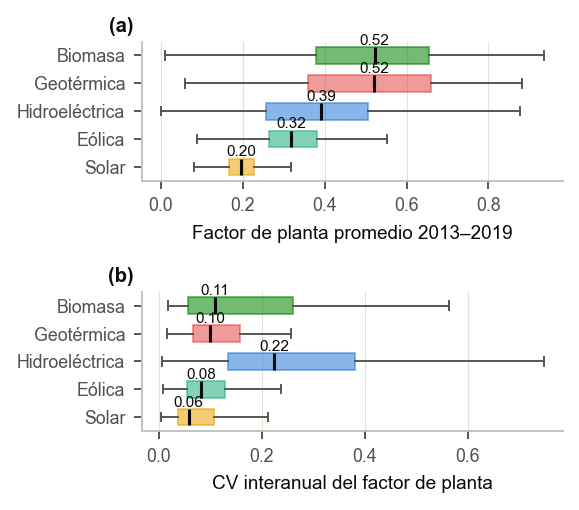

In [18]:
# Figura 1 del informe: rendimiento (FP) e inestabilidad (CV) por tecnología, sin atípicos dibujados
orden_fp = df_fp.groupby("tecnologia", observed=True)["factor_planta_prom"].median().sort_values().index.tolist()
with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(2, 1, figsize=(ANCHO_COLUMNA, 3.05))
    for ax, var, xlabel, letra in [(axes[0], "factor_planta_prom", "Factor de planta promedio 2013–2019", "(a)"),
                                   (axes[1], "cv_generacion", "CV interanual del factor de planta", "(b)")]:
        datos = [df_fp.loc[df_fp["tecnologia"] == t, var].dropna() for t in orden_fp]
        bp = ax.boxplot(datos, vert=False, patch_artist=True, widths=0.6, showfliers=False,
                        medianprops=dict(color=TINTA, linewidth=1.3), whiskerprops=dict(color=TINTA2, linewidth=0.8),
                        capprops=dict(color=TINTA2, linewidth=0.8))
        for caja, t in zip(bp["boxes"], orden_fp):
            caja.set(facecolor=TEC_COLOR[t], alpha=0.55, edgecolor=TEC_COLOR[t], linewidth=0.8)
        for y, d in enumerate(datos, start=1):
            ax.text(d.median(), y + 0.38, f"{d.median():.2f}", ha="center", fontsize=6.5, color=TINTA)
        ax.set_yticks(range(1, len(orden_fp) + 1), orden_fp)
        ax.set_xlabel(xlabel)
        ax.grid(axis="y", visible=False)
        etiqueta_panel(ax, letra)
    fig.tight_layout(h_pad=1.2)
    guardar_figura(fig, "fig1_rendimiento_estabilidad.png")
    plt.show()

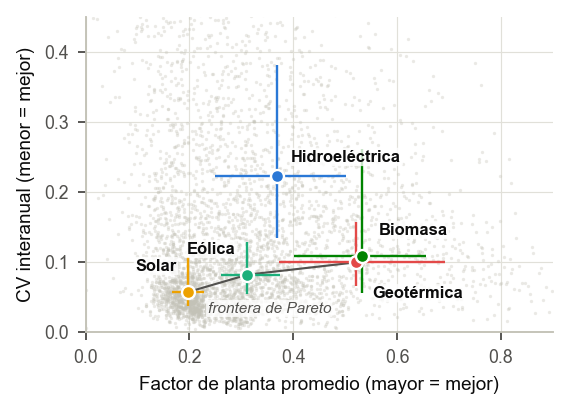

,fp,cv,fp_q1,fp_q3,cv_q1,cv_q3,n
tecnologia,,,,,,,
Solar,0.198,0.057,0.167,0.227,0.037,0.107,1646
Eólica,0.312,0.082,0.261,0.374,0.054,0.129,968
Hidroeléctrica,0.369,0.223,0.249,0.503,0.135,0.381,1676
Geotérmica,0.521,0.099,0.372,0.692,0.065,0.157,59
Biomasa,0.532,0.109,0.401,0.656,0.055,0.261,138


In [19]:
# Figura 2 del informe: mapa rendimiento–estabilidad (plantas con ≥ 3 años) y frontera de Pareto
sub = df_fp.dropna(subset=["cv_generacion"])
med = sub.groupby("tecnologia", observed=True).agg(
    fp=("factor_planta_prom", "median"), cv=("cv_generacion", "median"),
    fp_q1=("factor_planta_prom", lambda s: s.quantile(0.25)), fp_q3=("factor_planta_prom", lambda s: s.quantile(0.75)),
    cv_q1=("cv_generacion", lambda s: s.quantile(0.25)), cv_q3=("cv_generacion", lambda s: s.quantile(0.75)),
    n=("cv_generacion", "size"))
med.index = med.index.astype(str)
frontera = med.drop(index="Hidroeléctrica").sort_values("fp")        # la hidroeléctrica queda dominada
DESPLAZ = {"Solar": ((-5, 9), "right"), "Eólica": ((-5, 9), "right"), "Hidroeléctrica": ((6, 6), "left"),
           "Geotérmica": ((7, -15), "left"), "Biomasa": ((7, 9), "left")}      # posición de cada etiqueta
with plt.rc_context(ESTILO_INFORME):
    fig, ax = plt.subplots(figsize=(ANCHO_COLUMNA, 2.5))
    ax.scatter(sub["factor_planta_prom"], sub["cv_generacion"], s=2, color=GRIS, alpha=0.35, linewidths=0)
    ax.plot(frontera["fp"], frontera["cv"], color=TINTA2, linewidth=0.9, zorder=2)
    ax.text(0.235, 0.028, "frontera de Pareto", fontsize=6.5, color=TINTA2, style="italic", zorder=4,
            bbox=dict(boxstyle="round,pad=0.1", facecolor="white", edgecolor="none", alpha=0.8))
    for t, r in med.iterrows():
        ax.errorbar(r["fp"], r["cv"], xerr=[[r["fp"] - r["fp_q1"]], [r["fp_q3"] - r["fp"]]],
                    yerr=[[r["cv"] - r["cv_q1"]], [r["cv_q3"] - r["cv"]]], fmt="o", color=TEC_COLOR[t], markersize=5.5,
                    markeredgecolor="white", markeredgewidth=1, elinewidth=1, capsize=0, zorder=3)
        (dx, dy), ha = DESPLAZ[t]
        ax.annotate(t, (r["fp"], r["cv"]), xytext=(dx, dy), textcoords="offset points", fontsize=7,
                    fontweight="bold", color=TINTA, ha=ha, zorder=4,
                    bbox=dict(boxstyle="round,pad=0.1", facecolor="white", edgecolor="none", alpha=0.8))
    ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.45)
    ax.set_xlabel("Factor de planta promedio (mayor = mejor)")
    ax.set_ylabel("CV interanual (menor = mejor)")
    fig.tight_layout()
    guardar_figura(fig, "fig2_mapa_pareto.png")
    plt.show()
med.round(3)

**Interpretación**

- Kruskal-Wallis **rechaza H₀** con p ≈ 0 y un **tamaño de efecto grande**: la tecnología explica una parte importante de las diferencias de rendimiento. Levene confirma varianzas distintas, lo cual justifica la prueba no paramétrica.
- **Figura 1.** Hay una jerarquía clara de rendimiento mediano: **biomasa (0.52) ≈ geotérmica (0.52) > hidroeléctrica (0.39) > eólica (0.32) > solar (0.20)**. En las comparaciones por pares casi todas las diferencias son significativas; la excepción es **biomasa vs. geotérmica** (p = 1.0 tras Bonferroni), que comparten el primer lugar porque ambas pueden operar de forma **gestionable** (no dependen del sol ni del viento). La estabilidad sigue otro orden: la solar es la más estable (CV mediano 0.06) y la hidroeléctrica la más variable (0.22), porque depende de las lluvias.
- **Figura 2.** El mapa rendimiento–estabilidad es el hallazgo central de esta fase:
  - **Biomasa y geotérmica** tienen el mayor rendimiento (FP ≈ 0.52–0.53) con estabilidad aceptable (CV ≈ 0.10–0.11).
  - La **solar** es la más estable (CV 0.06), pero la de menor rendimiento (FP 0.20). La **eólica** queda en una posición intermedia (FP 0.31, CV 0.08).
  - La **hidroeléctrica** está **dominada**: la geotérmica y la biomasa tienen a la vez más rendimiento y menos variabilidad.
  - Las otras cuatro forman una **frontera de Pareto**: ninguna supera a las demás en todo, así que la respuesta a la pregunta principal depende de cómo se ponderen los criterios (sección 8).

## 7.2 Matrices de correlación: Pearson y Spearman (Figura 3 del informe)

- **Pearson (r)** mide relación **lineal** y es sensible a atípicos.
- **Spearman (ρ)** mide relación **monótona** sobre rangos y es robusta a atípicos y asimetrías.

Cuando ambas difieren mucho, la relación no es lineal o está dominada por valores extremos. Se calculan sobre las plantas con factor de planta; para compararlas en una sola figura, Pearson ocupa el triángulo inferior y Spearman el superior.

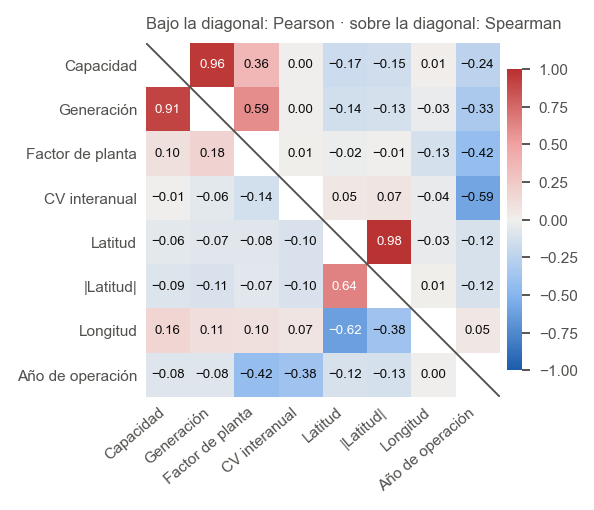

Pares con mayor diferencia Spearman − Pearson (señal de no linealidad o atípicos):
Longitud          Latitud      0.585
Factor de planta  Generación   0.406
Longitud          |Latitud|    0.384
|Latitud|         Latitud      0.343
Factor de planta  Capacidad    0.266


In [20]:
VARS_CORR = {"capacity_mw": "Capacidad", "generacion_prom_gwh": "Generación", "factor_planta_prom": "Factor de planta",
             "cv_generacion": "CV interanual", "latitude": "Latitud", "latitud_abs": "|Latitud|",
             "longitude": "Longitud", "anio_operacion": "Año de operación"}
datos_corr = df_fp[list(VARS_CORR)].rename(columns=VARS_CORR)
pearson = datos_corr.corr(method="pearson")
spearman = datos_corr.corr(method="spearman")

# Figura 3 del informe: Pearson bajo la diagonal y Spearman sobre ella
k = len(VARS_CORR)
inferior = np.tril(np.ones((k, k), dtype=bool), k=-1)
combinada = np.where(inferior, pearson.values, spearman.values)
np.fill_diagonal(combinada, np.nan)
with plt.rc_context(ESTILO_INFORME):
    fig, ax = plt.subplots(figsize=(ANCHO_COLUMNA, 3.15))
    im = ax.imshow(combinada, cmap=CMAP_DIV, vmin=-1, vmax=1)
    for i in range(k):
        for j in range(k):
            if i != j:
                v = 0.0 if abs(combinada[i, j]) < 0.005 else combinada[i, j]
                ax.text(j, i, f"{v:.2f}".replace("-", "−"), ha="center", va="center", fontsize=5.6,
                        color="white" if abs(v) > 0.6 else TINTA)
    ax.plot([-0.5, k - 0.5], [-0.5, k - 0.5], color=TINTA2, linewidth=0.8)      # separa los dos triángulos
    ax.set_xticks(range(k), list(VARS_CORR.values()), rotation=40, ha="right", fontsize=6.5)
    ax.set_yticks(range(k), list(VARS_CORR.values()), fontsize=6.5)
    ax.tick_params(length=0); ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_title("Bajo la diagonal: Pearson · sobre la diagonal: Spearman", fontsize=7, color=TINTA2, loc="left")
    barra = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    barra.ax.tick_params(labelsize=6.5); barra.outline.set_visible(False)
    fig.tight_layout()
    guardar_figura(fig, "fig3_correlaciones.png")
    plt.show()

dif = (spearman - pearson).where(inferior).stack()
print("Pares con mayor diferencia Spearman − Pearson (señal de no linealidad o atípicos):")
print(dif.reindex(dif.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

**Interpretación de las correlaciones**

- **Capacidad ↔ generación** (r = 0.91; ρ = 0.96): relación casi perfecta y esperable, porque una planta más grande genera más. Por eso **la generación absoluta no sirve para comparar eficiencia**, y se usa el factor de planta, que normaliza por capacidad.
- **Factor de planta ↔ CV interanual**: correlación **prácticamente nula** en el conjunto (r = −0.14; ρ = 0.01). Rendimiento y estabilidad son dimensiones **independientes**, y por eso deben medirse ambas.
- **Año de operación**: a nivel global, las plantas más recientes tienen **menor** FP (ρ = −0.42) y **menor** CV (ρ = −0.59). Es un **efecto de composición**: las plantas nuevas son en su mayoría solares (FP bajo y estable). La sección 7.3 muestra que dentro de la eólica la relación se invierte.
- **Pearson vs. Spearman**: la mayor diferencia aparece en **latitud ↔ longitud** (r = −0.62 vs. ρ = −0.03). No es una relación real sino un artefacto de la distribución espacial en grandes cúmulos (EE. UU., Europa y China). Siguen **FP ↔ generación** (0.18 vs. 0.59) y **FP ↔ capacidad** (0.10 vs. 0.36): relaciones monótonas que la asimetría de la capacidad oculta a Pearson. Conviene usar log10(capacidad).
- **Recordatorio**: *correlación no implica causalidad*. Estas asociaciones describen patrones y no prueban que una variable cause la otra.

## 7.3 Efectos que dependen de la tecnología: diagramas de dispersión (Figura 4 del informe)

La tabla calcula, dentro de cada tecnología, la correlación de Spearman del FP con la distancia al ecuador, el año de puesta en marcha y la capacidad. La figura 4 muestra los dos efectos más claros, con una tendencia LOWESS.

In [21]:
# ¿La latitud y el año se asocian con el FP dentro de cada tecnología? (Spearman con p-valor)
filas = []
for t, g in df_fp.groupby("tecnologia", observed=True):
    for var in ["latitud_abs", "anio_operacion", "capacity_mw"]:
        sub = g[[var, "factor_planta_prom"]].dropna()
        if len(sub) >= 30:
            rho, p = stats.spearmanr(sub[var], sub["factor_planta_prom"])
            filas.append({"tecnología": t, "variable": var, "n": len(sub), "ρ de Spearman": rho, "p-valor": p,
                          "significativa (α=0.05)": "Sí" if p < 0.05 else "No"})
corr_tec = pd.DataFrame(filas).pivot(index="tecnología", columns="variable", values="ρ de Spearman")
display(pd.DataFrame(filas).style.format({"n": "{:,.0f}", "ρ de Spearman": "{:.3f}", "p-valor": "{:.2e}"}).hide(axis="index"))

tecnología,variable,n,ρ de Spearman,p-valor,significativa (α=0.05)
Solar,latitud_abs,"2,702",-0.492,2.13e-164,Sí
Solar,anio_operacion,"2,691",0.081,2.68e-05,Sí
Solar,capacity_mw,"2,702",0.397,1.10e-102,Sí
Eólica,latitud_abs,"1,126",-0.105,4.03e-04,Sí
Eólica,anio_operacion,"1,077",0.459,2.60e-57,Sí
Eólica,capacity_mw,"1,126",0.322,1.64e-28,Sí
Hidroeléctrica,latitud_abs,"1,972",0.107,2.02e-06,Sí
Hidroeléctrica,anio_operacion,"1,825",-0.068,3.90e-03,Sí
Hidroeléctrica,capacity_mw,"1,972",-0.130,7.81e-09,Sí
Geotérmica,latitud_abs,66,-0.100,4.23e-01,No


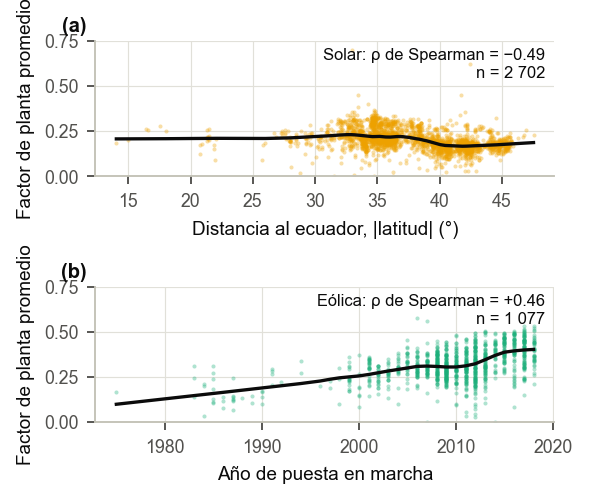

In [22]:
# Figura 4 del informe: (a) FP solar frente a la distancia al ecuador; (b) FP eólico frente al año de puesta en marcha
with plt.rc_context(ESTILO_INFORME):
    fig, axes = plt.subplots(2, 1, figsize=(ANCHO_COLUMNA, 3.0))
    for ax, t, var, xlabel, letra in [(axes[0], "Solar", "latitud_abs", "Distancia al ecuador, |latitud| (°)", "(a)"),
                                      (axes[1], "Eólica", "anio_operacion", "Año de puesta en marcha", "(b)")]:
        g = df_fp[df_fp["tecnologia"] == t][[var, "factor_planta_prom"]].dropna()
        ax.scatter(g[var], g["factor_planta_prom"], s=3, color=TEC_COLOR[t], alpha=0.35, linewidths=0)
        suav = lowess(g["factor_planta_prom"], g[var], frac=0.35)
        ax.plot(suav[:, 0], suav[:, 1], color=TINTA, linewidth=1.4)
        rho = stats.spearmanr(g[var], g["factor_planta_prom"])[0]
        ax.text(0.98, 0.95, f"{t}: ρ de Spearman = {rho:+.2f}\nn = {len(g):,}".replace(",", " ").replace("-", "−"),
                transform=ax.transAxes, ha="right", va="top", fontsize=7, color=TINTA)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Factor de planta promedio")
        ax.set_ylim(0, 0.75)
        etiqueta_panel(ax, letra)
    fig.tight_layout(h_pad=1.2)
    guardar_figura(fig, "fig4_efectos_por_tecnologia.png")
    plt.show()

**Interpretación**

- **Solar** (figura 4a): el FP cae al alejarse del ecuador (ρ = −0.49, menos radiación), sobre todo entre los 30° y los 42° (la nube solar con generación va de 14° a 47°, casi toda en EE. UU.). También crece con el tamaño de la planta (ρ = +0.40), posiblemente porque las grandes plantas usan seguidores solares y mejores sitios.
- **Eólica** (figura 4b): el FP mejora de forma sostenida en las plantas más recientes (ρ = +0.46), de ≈ 0.2 en los años noventa a ≈ 0.4 en 2018, y con el tamaño (ρ = +0.32).
- **Hidroeléctrica**: relaciones débiles (|ρ| ≤ 0.13), porque su rendimiento depende de variables ausentes como la hidrología o el tipo de central.
- **Geotérmica y biomasa**: sin asociaciones significativas, salvo el año en biomasa (ρ = −0.20); su n es pequeño.
- **Paradoja de Simpson**: en el conjunto, las plantas recientes rinden menos (ρ = −0.42, §7.2), pero dentro de la eólica rinden más (ρ = +0.46). Una correlación global puede tener el signo contrario a la que existe dentro de cada grupo. Por eso el análisis debe hacerse **por tecnología**, y los modelos deberán incluir interacciones tecnología × variable.

## 7.4 Pruebas de independencia χ² entre variables cualitativas (Tabla XI del informe)

Se verifica si la tecnología está asociada con la ubicación, la escala y el nivel de desempeño. Se reporta la **V de Cramér** (0 = sin asociación; ≥ 0.3 = asociación fuerte) y el % de celdas con frecuencia esperada < 5 (supuesto de la prueba: debe ser ≤ 20 %). La mareomotriz se excluye porque sus 10 plantas violarían ese supuesto.

In [23]:
sin_mareo = df[df["tecnologia"] != "Mareomotriz/undimotriz"].copy()
sin_mareo["tecnologia"] = sin_mareo["tecnologia"].cat.remove_unused_categories()
fp_sin_mareo = df_fp.copy()
fp_sin_mareo["tecnologia"] = fp_sin_mareo["tecnologia"].cat.remove_unused_categories()

chi2_tabla = pd.DataFrame([
    prueba_chi2(sin_mareo, "tecnologia", "zona_climatica"),
    prueba_chi2(sin_mareo, "tecnologia", "hemisferio"),
    prueba_chi2(sin_mareo, "tecnologia", "rango_capacidad"),
    prueba_chi2(sin_mareo, "tecnologia", "periodo_operacion"),
    prueba_chi2(fp_sin_mareo, "tecnologia", "nivel_desempeno"),
    prueba_chi2(fp_sin_mareo, "zona_climatica", "nivel_desempeno"),
])
chi2_tabla["conclusión (α=0.05)"] = np.where(chi2_tabla["p-valor"] < 0.05, "Dependientes", "Independientes")
chi2_tabla["fuerza"] = pd.cut(chi2_tabla["V de Cramér"], [0, 0.1, 0.3, 0.5, 1], labels=["Débil", "Moderada", "Fuerte", "Muy fuerte"])
chi2_tabla.style.format({"n": "{:,.0f}", "χ²": "{:,.1f}", "p-valor": "{:.2e}", "V de Cramér": "{:.3f}",
                         "% celdas esperada<5": "{:.1f}"}).hide(axis="index")

variables,n,χ²,gl,p-valor,V de Cramér,% celdas esperada<5,conclusión (α=0.05),fuerza
tecnologia × zona_climatica,"24,784","2,632.2",12,0.00e+00,0.188,0.0,Dependientes,Moderada
tecnologia × hemisferio,"24,784","1,947.6",4,0.00e+00,0.280,0.0,Dependientes,Moderada
tecnologia × rango_capacidad,"24,784","4,096.7",16,0.00e+00,0.203,4.0,Dependientes,Moderada
tecnologia × periodo_operacion,"10,276","8,228.1",16,0.00e+00,0.447,0.0,Dependientes,Fuerte
tecnologia × nivel_desempeno,"6,031","2,683.3",8,0.00e+00,0.472,0.0,Dependientes,Fuerte
zona_climatica × nivel_desempeno,"6,031",398.6,6,5.66e-83,0.182,0.0,Dependientes,Moderada


In [24]:
# Distribución por fila (%) de las tres asociaciones que se comentan abajo
for d, col, titulo in [(sin_mareo, "zona_climatica", "Tecnología × zona climática"),
                       (sin_mareo, "rango_capacidad", "Tecnología × rango de capacidad"),
                       (fp_sin_mareo, "nivel_desempeno", "Tecnología × nivel de desempeño")]:
    display(Markdown(f"**{titulo}** (% por fila)"))
    display((pd.crosstab(d["tecnologia"], d[col], normalize="index") * 100).round(1))

**Tecnología × zona climática** (% por fila)

zona_climatica,Tropical,Subtropical,Templada,Fría
tecnologia,,,,
Solar,9.500,18.400,71.900,0.200
Eólica,10.000,10.800,71.400,7.800
Hidroeléctrica,18.300,20.800,50.300,10.600
Geotérmica,22.800,15.900,57.700,3.700
Biomasa,39.300,10.200,44.400,6.100


**Tecnología × rango de capacidad** (% por fila)

rango_capacidad,1–5 MW,5–20 MW,20–100 MW,100–500 MW,≥500 MW
tecnologia,,,,,
Solar,38.100,37.700,20.900,3.100,0.200
Eólica,12.900,28.300,45.300,13.100,0.300
Hidroeléctrica,22.900,26.300,26.300,17.600,6.800
Geotérmica,3.700,25.400,51.300,18.000,1.600
Biomasa,38.000,30.100,27.300,4.500,0.100


**Tecnología × nivel de desempeño** (% por fila)

nivel_desempeno,Bajo,Medio,Alto
tecnologia,,,
Solar,57.300,41.400,1.400
Eólica,9.100,43.100,47.800
Hidroeléctrica,17.400,19.400,63.200
Geotérmica,6.100,10.600,83.300
Biomasa,8.500,10.300,81.200


**Interpretación de las pruebas χ²**

- En todos los casos se **rechaza la independencia** (p ≈ 0) y se cumple el supuesto de frecuencias esperadas (≤ 4 % de celdas con esperada < 5): tecnología, clima, escala, antigüedad y desempeño están asociados.
- **Tecnología × nivel de desempeño** es la asociación **más fuerte** (V = 0.47):
  - Solo el **1 %** de las plantas solares alcanza el tercil *Alto* (57 % están en *Bajo* y 41 % en *Medio*).
  - El 81–83 % de las plantas de biomasa y geotérmicas está en el tercil *Alto*.
  - La eólica se reparte entre *Medio* (43 %) y *Alto* (48 %), y la hidroeléctrica cubre los tres niveles (17 / 19 / 63 %).
  - Para la clasificación de la Fase 2, la tecnología será un predictor muy potente, pero no suficiente.
- **Tecnología × periodo de operación** (V = 0.45, fuerte): las hidroeléctricas son antiguas y las solares y eólicas, recientes. Esto explica la paradoja de Simpson de §7.3.
- **Tecnología × rango de capacidad** (V = 0.20): el 76 % de las solares y el 68 % de las de biomasa tienen ≤ 20 MW, la eólica y la geotérmica se concentran en 20–100 MW, y la hidroeléctrica ocupa todos los rangos, incluido un 7 % de megaproyectos de ≥ 500 MW.
- **Tecnología × zona climática** (V = 0.19): todas las tecnologías se concentran en la zona templada (reflejo de la cobertura del dataset), pero la **biomasa es la más tropical** (39 %, sobre todo plantas de Brasil) y la geotérmica tiene un 23 % tropical (Centroamérica, Indonesia y Filipinas).

## 7.5 Análisis multivariado

In [25]:
# (b) Factor de planta mediano según tecnología y zona climática (solo celdas con n ≥ 10)
piv_med = df_fp.pivot_table(index="tecnologia", columns="zona_climatica", values="factor_planta_prom", aggfunc="median", observed=True)
piv_n = df_fp.pivot_table(index="tecnologia", columns="zona_climatica", values="factor_planta_prom", aggfunc="count", observed=True)
piv_med = piv_med.where(piv_n >= 10)
display(Markdown("**Factor de planta mediano por tecnología y zona climática** (vacío: menos de 10 plantas)"))
display(piv_med.round(2))
display(Markdown("**Número de plantas con generación en cada celda**"))
piv_n.fillna(0).astype(int)

**Factor de planta mediano por tecnología y zona climática** (vacío: menos de 10 plantas)

zona_climatica,Tropical,Subtropical,Templada,Fría
tecnologia,,,,
Solar,0.200,0.220,0.190,NaN
Eólica,0.320,0.340,0.310,NaN
Hidroeléctrica,0.440,0.320,0.380,0.400
Geotérmica,NaN,0.650,0.490,NaN
Biomasa,0.390,0.550,0.510,NaN


**Número de plantas con generación en cada celda**

zona_climatica,Tropical,Subtropical,Templada,Fría
tecnologia,,,,
Solar,21,702,1979,0
Eólica,12,208,900,6
Hidroeléctrica,317,271,1340,44
Geotérmica,3,19,44,0
Biomasa,10,65,88,2


In [26]:
# (c) Análisis de componentes principales (PCA) sobre variables estandarizadas
VARS_PCA = ["capacity_mw", "latitud_abs", "anio_operacion", "factor_planta_prom", "cv_generacion"]
pca_df = df_fp.dropna(subset=VARS_PCA).copy()
X_pca = pca_df[VARS_PCA].assign(capacity_mw=np.log10(pca_df["capacity_mw"]))
Z = StandardScaler().fit_transform(X_pca)
pca = PCA(random_state=SEMILLA).fit(Z)
comp = pca.transform(Z)

varianza = pd.DataFrame({"varianza explicada (%)": pca.explained_variance_ratio_ * 100,
                         "acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100},
                        index=[f"PC{i + 1}" for i in range(len(VARS_PCA))])
cargas = pd.DataFrame(pca.components_[:3].T, index=["log10(capacidad)"] + VARS_PCA[1:], columns=["PC1", "PC2", "PC3"])
display(varianza.round(1)); display(cargas.round(3))

# Posición mediana de cada nivel de desempeño en las dos primeras componentes
pd.DataFrame({"nivel de desempeño": pca_df["nivel_desempeno"].astype(str).values, "PC1": comp[:, 0], "PC2": comp[:, 1]})\
  .groupby("nivel de desempeño")[["PC1", "PC2"]].median().reindex(["Bajo", "Medio", "Alto"]).round(2)

,varianza explicada (%),acumulada (%)
PC1,32.200,32.200
PC2,24.700,56.900
PC3,22.900,79.900
PC4,13.100,93.000
PC5,7.000,100.000


,PC1,PC2,PC3
log10(capacidad),-0.272,0.025,0.747
latitud_abs,-0.221,-0.498,-0.561
anio_operacion,0.679,-0.205,0.172
factor_planta_prom,-0.593,-0.382,0.175
cv_generacion,-0.254,0.751,-0.260


,PC1,PC2
nivel de desempeño,,
Bajo,1.230,-0.040
Medio,0.570,-0.190
Alto,-1.010,-0.630


**Interpretación multivariada**

- **Tecnología × clima**: la solar (0.22), la eólica (0.34), la geotérmica (0.65, n = 19) y la biomasa (0.55) alcanzan su mejor rendimiento mediano en la zona **subtropical**, y la hidroeléctrica en la **tropical** (0.44). El orden de las tecnologías se mantiene en todas las zonas, pero las brechas cambian. Esa interacción entre tecnología y ubicación será clave para la regresión. Las celdas con pocas plantas deben leerse con cautela.
- **PCA**: tres componentes explican el 80 % de la varianza, señal de que el problema es genuinamente **multidimensional**.
  - **PC1** (32 %) es un eje *antigüedad ↔ rendimiento*: en un extremo, las plantas recientes (mayoritariamente solares) de FP bajo; en el otro, las antiguas de FP alto.
  - **PC2** (25 %) es un eje de *inestabilidad*: carga positiva del CV y negativa de la latitud y el FP.
  - Los niveles de desempeño se separan a lo largo de PC1 (última tabla), lo que anticipa que el clustering encontrará segmentos con sentido.

# 8. Índice exploratorio de desempeño integral (Tabla XII del informe)

Con las cuatro dimensiones definidas en §2.1 se construye un índice **preliminar**:

1. Cada dimensión se calcula por tecnología y se normaliza a [0, 1] con *min-max*: 1 = la mejor y 0 = la más baja del grupo. Un 0 no significa ausencia de desempeño; por ejemplo, la solar recibe 0 en rendimiento porque su FP mediano (0.20) es el más bajo de las cinco.
2. El índice base pondera las cuatro dimensiones por igual.
3. Como el resultado depende de los pesos, se hace un **análisis de sensibilidad**: se generan 10 000 combinaciones aleatorias de pesos (distribución de Dirichlet) y se cuenta cuántas veces cada tecnología queda en primer lugar.

La mareomotriz se excluye porque no tiene datos de rendimiento. **Este índice es exploratorio**: en las fases 3 y 4 se incorporarán costo (LCOE, IRENA) y emisiones de ciclo de vida (IPCC).

In [27]:
d_idx = df[df["tecnologia"] != "Mareomotriz/undimotriz"]
indice = pd.DataFrame({
    "Rendimiento (FP mediano)": df_fp.groupby("tecnologia", observed=True)["factor_planta_prom"].median(),
    "Estabilidad (1 − CV mediano)": 1 - df_fp.groupby("tecnologia", observed=True)["cv_generacion"].median(),
    "Versatilidad (n.º países)": d_idx.groupby("tecnologia", observed=True)["country"].nunique(),
    "Dinamismo (% plantas desde 2010)": d_idx.dropna(subset=["anio_operacion"]).groupby("tecnologia", observed=True)["anio_operacion"].apply(lambda s: (s >= 2010).mean() * 100),
})
indice.index = indice.index.astype(str)
indice = indice.loc[TEC_CON_GENERACION]
display(Markdown("**Valores originales por dimensión**"))
display(indice.round(3))

norm = (indice - indice.min()) / (indice.max() - indice.min())
norm["Índice (pesos iguales)"] = norm.mean(axis=1)
norm = norm.sort_values("Índice (pesos iguales)", ascending=False)

# Sensibilidad: 10 000 vectores de pesos aleatorios
pesos = rng.dirichlet(np.ones(4), size=10_000)
puntajes = norm.iloc[:, :4].values @ pesos.T                     # tecnologías × simulaciones
ganador = pd.Series(np.array(norm.index)[puntajes.argmax(axis=0)]).value_counts(normalize=True) * 100
ganador = ganador.reindex(norm.index).fillna(0)
rango_medio = pd.Series((-puntajes).argsort(axis=0).argsort(axis=0).mean(axis=1) + 1, index=norm.index)

display(Markdown("**Dimensiones normalizadas (1 = la mejor; 0 = la más baja del grupo) e índice con pesos iguales**"))
display(norm.round(2))

resumen_indice = pd.DataFrame({"índice (pesos iguales)": norm["Índice (pesos iguales)"],
                               "% veces n.º 1": ganador, "puesto promedio": rango_medio}).round(3)
resumen_indice

**Valores originales por dimensión**

,Rendimiento (FP mediano),Estabilidad (1 − CV mediano),Versatilidad (n.º países),Dinamismo (% plantas desde 2010)
tecnologia,,,,
Solar,0.196,0.943,92,98.057
Eólica,0.318,0.918,58,56.522
Hidroeléctrica,0.392,0.777,128,13.774
Geotérmica,0.520,0.901,22,21.678
Biomasa,0.522,0.891,38,33.162


**Dimensiones normalizadas (1 = la mejor; 0 = la más baja del grupo) e índice con pesos iguales**

,Rendimiento (FP mediano),Estabilidad (1 − CV mediano),Versatilidad (n.º países),Dinamismo (% plantas desde 2010),Índice (pesos iguales)
tecnologia,,,,,
Solar,0.000,1.000,0.660,1.000,0.670
Eólica,0.370,0.850,0.340,0.510,0.520
Biomasa,1.000,0.690,0.150,0.230,0.520
Geotérmica,0.990,0.750,0.000,0.090,0.460
Hidroeléctrica,0.600,0.000,1.000,0.000,0.400


,índice (pesos iguales),% veces n.º 1,puesto promedio
tecnologia,,,
Solar,0.665,62.500,1.956
Eólica,0.518,0.000,2.932
Biomasa,0.517,22.700,2.653
Geotérmica,0.458,2.900,3.705
Hidroeléctrica,0.400,11.900,3.753


**Interpretación del índice exploratorio**

- Con pesos iguales, ninguna tecnología obtiene un puntaje cercano a 1: **no existe una renovable "perfecta"**, porque cada una sobresale en dimensiones distintas.
- La **solar** lidera el índice con pesos iguales (0.67) y es la n.º 1 en el **62.5 %** de las 10 000 ponderaciones aleatorias. Su ventaja viene de la estabilidad, el dinamismo de adopción y la versatilidad geográfica, **pese a tener el menor factor de planta**.
- La **biomasa** gana en el 22.7 % de las ponderaciones (cuando pesa mucho el rendimiento) y la **hidroeléctrica** en el 11.9 % (cuando pesa mucho la versatilidad). La **eólica** casi empata con la biomasa en el índice de pesos iguales (0.52), pero nunca queda primera: es "segunda en todo".
- **Precaución**:
  - El dinamismo solar se calcula sobre las 3 500 solares con año conocido, de las cuales el 94 % está en EE. UU.
  - La versatilidad y el dinamismo reflejan el despliegue histórico, no el potencial técnico.
  - Faltan criterios clave: costo (LCOE) y emisiones de ciclo de vida, donde la biomasa, por ejemplo, tiene desventajas conocidas por la combustión y el uso de suelo.
  - En las fases 3 y 4 el índice se recalculará con esas dimensiones y con los resultados de los modelos.

# 9. Verificación de la versatilidad del dataset (Tabla XIII del informe)

La guía (§2.2) exige que el dataset permita **regresión, clasificación y clustering** a la vez, y el plan del curso propone ensayar un primer modelo. Esta sección hace una prueba de concepto **rápida y sin fuga de datos** para confirmar la viabilidad y fijar metas SMART realistas.

> ⚠️ **No reemplaza el Entregable 2.** La limpieza, la ingeniería de variables, la partición train/val/test y el modelo base formales se desarrollarán en la Fase 2.

| Tarea | Variable objetivo | Tipo | Plantas disponibles | Predictores candidatos |
|---|---|---|---|---|
| Regresión | `factor_planta_prom` | Continua (0, 1] | ≈ 6 000 | tecnología, log10(capacidad), latitud, longitud, \|latitud\|, año de operación |
| Clasificación | `nivel_desempeno` (Bajo/Medio/Alto) o `tecnologia` | Categórica ordinal / nominal | ≈ 6 000 / 24 794 | los mismos, **sin** generación (evita fuga) |
| Clustering | — (no supervisado) | — | ≈ 5 800 con datos completos | log10(capacidad), \|latitud\|, año, factor de planta, CV |

## 9.1 Regresión lineal simple: factor de planta solar vs. distancia al ecuador

Se estima $\widehat{FP} = \beta_0 + \beta_1 \cdot |\text{latitud}|$ por mínimos cuadrados ordinarios, solo para plantas solares.

In [28]:
solar = df_fp[df_fp["tecnologia"] == "Solar"][["factor_planta_prom", "latitud_abs"]].dropna()
mod_simple = smf.ols("factor_planta_prom ~ latitud_abs", data=solar).fit()
print(mod_simple.summary().tables[1])
print(f"\nR² = {mod_simple.rsquared:.3f} | n = {int(mod_simple.nobs):,}")
b0, b1 = mod_simple.params
print(f"Interpretación: β1 = {b1:.4f} indica que por cada grado adicional de distancia al ecuador el FP solar "
      f"cambia en {b1 * 100:.2f} puntos porcentuales (unos {abs(b1) * 10 * 100:.0f} puntos cada 10°).")
print(f"β0 = {b0:.3f} sería el FP en el ecuador, pero el rango observado de |latitud| solar es "
      f"{solar['latitud_abs'].min():.1f}° – {solar['latitud_abs'].max():.1f}°: interpretarlo sería EXTRAPOLAR, "
      "y la recta solo es confiable dentro del rango de los datos.")
print("La nube de puntos y su tendencia se muestran en la figura 4(a) del informe (§7.3).")

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.3873      0.009     44.608      0.000       0.370       0.404
latitud_abs    -0.0049      0.000    -21.550      0.000      -0.005      -0.004

R² = 0.147 | n = 2,702
Interpretación: β1 = -0.0049 indica que por cada grado adicional de distancia al ecuador el FP solar cambia en -0.49 puntos porcentuales (unos 5 puntos cada 10°).
β0 = 0.387 sería el FP en el ecuador, pero el rango observado de |latitud| solar es 14.0° – 47.5°: interpretarlo sería EXTRAPOLAR, y la recta solo es confiable dentro del rango de los datos.
La nube de puntos y su tendencia se muestran en la figura 4(a) del informe (§7.3).


## 9.2 Regresión lineal múltiple con variable categórica

Se agregan la tecnología (variables *dummy*, con la **solar** como categoría de referencia), la escala y la antigüedad. En esta prueba se usan solo los casos completos; la imputación se decidirá en la Fase 2.

In [29]:
dm = df_fp.dropna(subset=["anio_operacion"]).assign(log_cap=lambda d: np.log10(d["capacity_mw"]))
dm["tecnologia"] = dm["tecnologia"].cat.remove_unused_categories()
mod_mult = smf.ols("factor_planta_prom ~ C(tecnologia, Treatment('Solar')) + log_cap + latitud_abs + anio_operacion", data=dm).fit()
tabla_coef = pd.DataFrame({"coeficiente": mod_mult.params, "error estándar": mod_mult.bse, "t": mod_mult.tvalues,
                           "p-valor": mod_mult.pvalues, "IC 2.5 %": mod_mult.conf_int()[0], "IC 97.5 %": mod_mult.conf_int()[1]})
tabla_coef.index = tabla_coef.index.str.replace(r"C\(tecnologia, Treatment\('Solar'\)\)\[T\.", "Tecnología: ", regex=True).str.replace("]", "")
display(tabla_coef.style.format({c: "{:.4f}" for c in tabla_coef.columns} | {"p-valor": "{:.2e}", "t": "{:.2f}"}))
print(f"R² = {mod_mult.rsquared:.3f} | R² ajustado = {mod_mult.rsquared_adj:.3f} | n = {int(mod_mult.nobs):,}")

,coeficiente,error estándar,t,p-valor,IC 2.5 %,IC 97.5 %
Intercept,1.3175,0.1826,7.21,6.17e-13,0.9594,1.6755
Tecnología: Eólica,0.1050,0.0049,21.26,1.12e-96,0.0953,0.1147
Tecnología: Hidroeléctrica,0.1593,0.0059,27.21,1.60e-153,0.1479,0.1708
Tecnología: Geotérmica,0.2873,0.0150,19.19,1.21e-79,0.2580,0.3167
Tecnología: Biomasa,0.3006,0.0099,30.26,6.36e-187,0.2811,0.3200
log_cap,0.0138,0.0024,5.68,1.40e-08,0.0090,0.0185
latitud_abs,-0.0004,0.0002,-1.59,1.12e-01,-0.0008,0.0001
anio_operacion,-0.0006,0.0001,-6.17,7.20e-10,-0.0007,-0.0004


R² = 0.404 | R² ajustado = 0.403 | n = 5,816


**Lectura del modelo múltiple** (R² ≈ 0.40)

- Cada coeficiente de tecnología es la diferencia de FP esperada **frente a una planta solar** con la misma capacidad, latitud y año. En igualdad de condiciones, la eólica rinde ≈ +0.10, la hidroeléctrica ≈ +0.16, la geotérmica ≈ +0.29 y la biomasa ≈ +0.30 puntos de FP más que la solar. Todos los IC 95 % excluyen el cero.
- `log_cap` es positivo y significativo: las plantas más grandes rinden algo más.
- `latitud_abs` **deja de ser significativa** (p ≈ 0.11) al mezclar tecnologías, porque su efecto es negativo en la solar y positivo en la hidroeléctrica, y ambos se cancelan. Es la misma lección de la paradoja de Simpson: en la Fase 2 se necesitan **términos de interacción** (tecnología × latitud) o modelos no lineales.

## 9.3 Comparación preliminar de modelos (partición 75 / 25, `random_state = 42`)

Siguiendo la práctica habitual, se separa un 25 % de datos que el modelo **nunca ve** durante el entrenamiento, y las métricas (R², RMSE, MAE) se calculan sobre ese conjunto de prueba. Además se repite con **validación cruzada de 5 particiones** para verificar que el resultado no dependa de una sola partición. Toda transformación (imputación, codificación) se ajusta **dentro del *pipeline***, solo con datos de entrenamiento.

In [30]:
CAT, NUM = ["tecnologia"], ["log_cap", "latitude", "longitude", "latitud_abs", "anio_operacion"]
datos_ml = df_fp.assign(log_cap=np.log10(df_fp["capacity_mw"]))
datos_ml["tecnologia"] = datos_ml["tecnologia"].astype(str)
X, y = datos_ml[CAT + NUM], datos_ml["factor_planta_prom"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=X["tecnologia"])

prep_lineal = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CAT),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("esc", StandardScaler())]), NUM)])
prep_arbol = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", "passthrough", NUM)])

modelos_reg = {
    "Dummy (predice la media)": DummyRegressor(strategy="mean"),
    "Lineal: solo tecnología": Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CAT)])),
                                         ("mod", LinearRegression())]),
    "Lineal múltiple": Pipeline([("prep", prep_lineal), ("mod", LinearRegression())]),
    "Gradient Boosting (HistGB)": Pipeline([("prep", prep_arbol), ("mod", HistGradientBoostingRegressor(random_state=SEMILLA))]),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
res_reg = []
for nombre, modelo in modelos_reg.items():
    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_te)
    r2_cv = cross_val_score(modelo, X_tr, y_tr, cv=cv, scoring="r2")
    res_reg.append({"modelo": nombre, "R² prueba": r2_score(y_te, pred), "RMSE prueba": np.sqrt(mean_squared_error(y_te, pred)),
                    "MAE prueba": mean_absolute_error(y_te, pred), "R² CV (media)": r2_cv.mean(), "R² CV (desv.)": r2_cv.std()})
res_reg = pd.DataFrame(res_reg)
print(f"Entrenamiento: {len(X_tr):,} plantas | Prueba: {len(X_te):,} plantas")
res_reg.style.format({c: "{:.3f}" for c in res_reg.columns if c != "modelo"}).hide(axis="index")

Entrenamiento: 4,523 plantas | Prueba: 1,508 plantas


modelo,R² prueba,RMSE prueba,MAE prueba,R² CV (media),R² CV (desv.)
Dummy (predice la media),-0.001,0.160,0.124,-0.001,0.001
Lineal: solo tecnología,0.382,0.126,0.087,0.354,0.015
Lineal múltiple,0.402,0.124,0.084,0.373,0.012
Gradient Boosting (HistGB),0.588,0.103,0.065,0.571,0.035


## 9.4 Clasificación preliminar del nivel de desempeño

Para evitar fuga de datos, los **cortes de los terciles se calculan solo con el conjunto de entrenamiento** y luego se aplican al de prueba.

In [31]:
cortes = y_tr.quantile([1/3, 2/3]).values
a_clase = lambda v: pd.cut(v, [-np.inf, cortes[0], cortes[1], np.inf], labels=["Bajo", "Medio", "Alto"]).astype(str)
yc_tr, yc_te = a_clase(y_tr), a_clase(y_te)
print(f"Cortes (solo entrenamiento): Bajo < {cortes[0]:.3f} ≤ Medio < {cortes[1]:.3f} ≤ Alto")

modelos_clf = {
    "Dummy (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Gradient Boosting (HistGB)": Pipeline([("prep", prep_arbol), ("mod", HistGradientBoostingClassifier(random_state=SEMILLA))]),
}
res_clf = []
for nombre, modelo in modelos_clf.items():
    modelo.fit(X_tr, yc_tr)
    pred = modelo.predict(X_te)
    res_clf.append({"modelo": nombre, "Accuracy prueba": accuracy_score(yc_te, pred), "F1-macro prueba": f1_score(yc_te, pred, average="macro")})
res_clf = pd.DataFrame(res_clf)
res_clf.style.format({"Accuracy prueba": "{:.3f}", "F1-macro prueba": "{:.3f}"}).hide(axis="index")

Cortes (solo entrenamiento): Bajo < 0.205 ≤ Medio < 0.322 ≤ Alto


modelo,Accuracy prueba,F1-macro prueba
Dummy (clase más frecuente),0.348,0.172
Gradient Boosting (HistGB),0.754,0.752


## 9.5 Clustering preliminar (K-Means): método del codo y coeficiente de silueta

In [32]:
ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z, km.labels_, sample_size=min(4000, len(Z)), random_state=SEMILLA))

k_mejor = list(ks)[int(np.argmax(silueta))]
display(Markdown(f"**Método del codo y coeficiente de silueta** (K-Means sobre {len(Z):,} plantas, variables de la PCA estandarizadas)"))
display(pd.DataFrame({"k": list(ks), "inercia": inercia, "silueta": silueta})
        .style.format({"inercia": "{:,.0f}", "silueta": "{:.3f}"}).hide(axis="index"))
print(f"Silueta máxima = {max(silueta):.3f} con k = {k_mejor}")

perfil = pca_df.assign(cluster=KMeans(n_clusters=k_mejor, n_init=10, random_state=SEMILLA).fit_predict(Z))
display(Markdown(f"**Perfil preliminar de los {k_mejor} clústeres** (medianas y tecnología dominante)"))
perfil.groupby("cluster").agg(plantas=("gppd_idnr", "size"), capacidad_mw=("capacity_mw", "median"),
                              latitud_abs=("latitud_abs", "median"), anio=("anio_operacion", "median"),
                              factor_planta=("factor_planta_prom", "median"), cv=("cv_generacion", "median"),
                              tecnologia_dominante=("tecnologia", lambda s: s.value_counts().index[0]),
                              pct_dominante=("tecnologia", lambda s: s.value_counts(normalize=True).iloc[0] * 100))

**Método del codo y coeficiente de silueta** (K-Means sobre 4,336 plantas, variables de la PCA estandarizadas)

k,inercia,silueta
2,"16,456",0.321
3,"13,344",0.293
4,"10,724",0.316
5,"9,457",0.326
6,"8,628",0.313
7,"7,902",0.304
8,"7,301",0.313


Silueta máxima = 0.326 con k = 5


**Perfil preliminar de los 5 clústeres** (medianas y tecnología dominante)

,plantas,capacidad_mw,latitud_abs,anio,factor_planta,cv,tecnologia_dominante,pct_dominante
cluster,,,,,,,,
0,129,75.000,18.937,"1,987.000",0.252,0.291,Hidroeléctrica,88.372
1,1120,98.800,37.749,"2,010.000",0.321,0.074,Eólica,57.589
2,484,8.450,38.297,"1,976.000",0.227,0.510,Hidroeléctrica,82.851
3,789,8.000,43.532,"1,950.000",0.523,0.158,Hidroeléctrica,88.720
4,1814,2.600,38.850,"2,013.000",0.203,0.070,Solar,77.784


In [33]:
versatilidad = pd.DataFrame([
    {"tarea": "Regresión (FP)", "baseline": "Dummy / lineal solo tecnología",
     "métrica": "R² prueba", "baseline_valor": res_reg.iloc[1]["R² prueba"], "mejor_preliminar": res_reg["R² prueba"].max(), "meta SMART": 0.55},
    {"tarea": "Clasificación (nivel de desempeño)", "baseline": "Dummy",
     "métrica": "F1-macro prueba", "baseline_valor": res_clf.iloc[0]["F1-macro prueba"], "mejor_preliminar": res_clf["F1-macro prueba"].max(), "meta SMART": 0.70},
    {"tarea": "Clustering (K-Means)", "baseline": "—",
     "métrica": "Silueta", "baseline_valor": np.nan, "mejor_preliminar": max(silueta), "meta SMART": 0.35},
])
display(Markdown("**Prueba de concepto frente a las metas SMART (Tabla XIII del informe)**"))
versatilidad.style.format({"baseline_valor": "{:.3f}", "mejor_preliminar": "{:.3f}", "meta SMART": "{:.2f}"}, na_rep="—").hide(axis="index")

**Prueba de concepto frente a las metas SMART (Tabla XIII del informe)**

tarea,baseline,métrica,baseline_valor,mejor_preliminar,meta SMART
Regresión (FP),Dummy / lineal solo tecnología,R² prueba,0.382,0.588,0.55
Clasificación (nivel de desempeño),Dummy,F1-macro prueba,0.172,0.752,0.70
Clustering (K-Means),—,Silueta,—,0.326,0.35


**Conclusión de la prueba de concepto**: el dataset **cumple la condición de versatilidad** de la guía.

- **Regresión**: el *Gradient Boosting* sin ajustar alcanza R² = 0.59 en prueba (RMSE ≈ 0.10, MAE ≈ 0.065), frente a 0.38 del modelo lineal con solo la tecnología. La validación cruzada da un valor similar (0.57 ± 0.04), así que el resultado no depende de una partición afortunada. La brecha entre el modelo lineal (0.40) y el no lineal confirma que hay **interacciones y no linealidades** que modelar.
- **Clasificación**: F1-macro = 0.75, frente a 0.17 del clasificador *Dummy*.
- **Clustering**: la silueta máxima (0.33 con k = 5) queda algo por debajo de la meta de 0.35. Aun así, los 5 segmentos ya tienen sentido físico:
  - pequeñas solares recientes y estables;
  - eólicas grandes y recientes;
  - hidroeléctricas antiguas de alto FP;
  - pequeñas hidroeléctricas muy inestables (CV ≈ 0.5);
  - hidroeléctricas de baja latitud.

  En la Fase 3 se mejorará con selección de variables, DBSCAN o clustering jerárquico.
- Las metas SMART (R² ≥ 0.55, F1-macro ≥ 0.70, silueta ≥ 0.35) son **exigentes pero alcanzables**.

# 10. Contraste mundial: las ocho categorías de Enel

La GPPD cubre las seis fuentes primarias de Enel, pero deja tres vacíos (§2.1): la **energía marina** tiene solo 10 plantas y ninguna con generación reportada, el **hidrógeno** no aparece y el **almacenamiento** se excluyó porque no genera energía. Para completar el panorama se usan dos fuentes complementarias. No reemplazan a la GPPD, que sigue siendo el dataset principal del proyecto: sirven para **contrastar** sus resultados con datos mundiales y para describir las tres categorías que faltan.

| Campo | IRENASTAT | Base de proyectos de producción de hidrógeno |
|---|---|---|
| Publicador | Agencia Internacional de Energías Renovables (IRENA) | Agencia Internacional de Energía (IEA) |
| Contenido | Capacidad instalada (MW) y generación (GWh) por tecnología, región y país, 2000–2025 | Proyectos de hidrógeno de bajas emisiones desde 2000: tecnología, fuente de electricidad, estado, capacidad (MWel) y país |
| Repositorio | Portal oficial de datos de IRENA, consultado con su API PxWeb | Kaggle (copia de la edición 2024 de la IEA); la IEA pide una cuenta gratuita para descargar ediciones posteriores |
| URL | https://pxweb.irena.org/pxweb/en/IRENASTAT | https://www.kaggle.com/datasets/syedbaqarx/iea-hydrogen-production-projects-database |
| Edición | 2026-H2 (actualizada el 28 de septiembre de 2026) | IEA (2024), *Hydrogen Production Projects Database* |
| Fecha de extracción | 24 de octubre de 2026 | 24 de octubre de 2026 |
| Licencia | Uso libre con atribución a IRENA | CC BY 4.0 |
| Unidad de análisis | Agregado mundial por tecnología y año (no por planta) | Proyecto |

**Método.** El FP mundial de cada tecnología se calcula con la **capacidad media del año**, para no subestimarlo en las tecnologías que crecen rápido (una planta que entra en diciembre suma capacidad, pero casi no genera ese año):

$$FP_t = \frac{E_t\ [\text{GWh}]}{8{,}76 \times \tfrac{1}{2}\left(P_t + P_{t-1}\right)\ [\text{MW}]}$$

Es un promedio **ponderado por capacidad**, no una mediana por planta como en la GPPD; por eso, entre las dos fuentes se comparan **órdenes**, no valores exactos.

## 10.1 Descarga y carga de las fuentes complementarias

Igual que con la GPPD, el código busca los archivos en `data/raw/` y solo los descarga si no existen. IRENASTAT se consulta con su API oficial (se pide la última edición disponible), y la base de hidrógeno se descarga de Kaggle.

In [34]:
import json

API_IRENA = "https://pxweb.irena.org/api/v1/en/IRENASTAT/Power%20Capacity%20and%20Generation"
DIR_IRENA = RAIZ / "data" / "raw" / "irenastat"
RUTA_IRENA_MUNDO = DIR_IRENA / "irenastat_mundo_por_tecnologia.csv"
RUTA_IRENA_MARINA = DIR_IRENA / "irenastat_energia_marina_por_pais.csv"
RUTA_IRENA_PAISES = DIR_IRENA / "irenastat_paises_2023_2024.csv"
URL_H2 = "https://www.kaggle.com/api/v1/datasets/download/syedbaqarx/iea-hydrogen-production-projects-database"
DIR_H2 = RAIZ / "data" / "raw" / "iea_hidrogeno"
RUTA_H2 = DIR_H2 / "projects.csv"


def irena_get(ruta=""):
    with urllib.request.urlopen(f"{API_IRENA}/{ruta}", timeout=120) as r:
        return json.load(r)


def irena_consulta(tabla, seleccion):
    # seleccion: {variable: textos que se incluyen}; las variables que no aparecen se piden completas
    consulta = []
    for v in irena_get(tabla)["variables"]:
        textos = seleccion.get(v["code"])
        codigos = v["values"] if textos is None else [c for c, t in zip(v["values"], v["valueTexts"]) if t in textos]
        consulta.append({"code": v["code"], "selection": {"filter": "item", "values": codigos}})
    cuerpo = json.dumps({"query": consulta, "response": {"format": "csv"}}).encode()
    pedido = urllib.request.Request(f"{API_IRENA}/{tabla}", data=cuerpo, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(pedido, timeout=180) as r:
        return r.read()


if not (RUTA_IRENA_MUNDO.exists() and RUTA_IRENA_MARINA.exists()):
    DIR_IRENA.mkdir(parents=True, exist_ok=True)
    tablas = [t["id"] for t in irena_get()]
    t_region = sorted(t for t in tablas if t.startswith("Region_ELECSTAT"))[-1]
    t_pais = sorted(t for t in tablas if t.startswith("Country_ELECSTAT"))[-1]
    print("Descargando de IRENASTAT:", t_region, "y", t_pais)
    RUTA_IRENA_MUNDO.write_bytes(irena_consulta(t_region, {"Region": ["World"]}))
    RUTA_IRENA_MARINA.write_bytes(irena_consulta(t_pais, {"Technology": ["Marine energy"],
                                                          "Grid connection": ["All"], "Year": ["2015", "2024"]}))

if not RUTA_IRENA_PAISES.exists():
    DIR_IRENA.mkdir(parents=True, exist_ok=True)
    t_pais = sorted(t["id"] for t in irena_get() if t["id"].startswith("Country_ELECSTAT"))[-1]
    print("Descargando de IRENASTAT, por país:", t_pais)
    RUTA_IRENA_PAISES.write_bytes(irena_consulta(t_pais, {
        "Technology": ["Total Renewable", "Total Non-Renewable", "Solar photovoltaic", "Onshore wind energy",
                       "Offshore wind energy", "Geothermal energy", "Renewable hydropower"],
        "Grid connection": ["All"], "Year": ["2023", "2024"]}))

if not RUTA_H2.exists():
    DIR_H2.mkdir(parents=True, exist_ok=True)
    ruta_zip = DIR_H2 / "iea_hydrogen_projects_kaggle.zip"
    print("Descargando la base de proyectos de hidrógeno de la IEA (copia en Kaggle) ...")
    urllib.request.urlretrieve(URL_H2, ruta_zip)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extract(RUTA_H2.name, DIR_H2)


def leer_irena(ruta, columnas):
    d = pd.read_csv(ruta, encoding="latin-1")          # IRENA entrega el CSV en Latin-1
    d.columns = columnas
    d["valor"] = pd.to_numeric(d["valor"], errors="coerce")
    d["anio"] = d["anio"].astype(int)
    return d


irena = leer_irena(RUTA_IRENA_MUNDO, ["region", "tecnologia", "tipo", "anio", "valor"])
marina_paises = leer_irena(RUTA_IRENA_MARINA, ["pais", "tecnologia", "tipo", "red", "anio", "valor"])
paises_irena = leer_irena(RUTA_IRENA_PAISES, ["pais", "tecnologia", "tipo", "red", "anio", "valor"])
h2 = pd.read_csv(RUTA_H2, low_memory=False)

for ruta in (RUTA_IRENA_MUNDO, RUTA_IRENA_MARINA, RUTA_IRENA_PAISES, RUTA_H2):
    print(f"{ruta.name}: {ruta.stat().st_size / 1e3:,.0f} kB | SHA-256 {hashlib.sha256(ruta.read_bytes()).hexdigest()}")
print(f"\nIRENASTAT: {irena['tecnologia'].nunique()} tecnologías, años {irena['anio'].min()}–{irena['anio'].max()}")
print(f"IEA hidrógeno: {len(h2):,} proyectos × {h2.shape[1]} columnas")

irenastat_mundo_por_tecnologia.csv: 45 kB | SHA-256 71aaa8a4bd03781927283bdacce8ebd1ff6ad70b336d40cb4baef401047a03b4
irenastat_energia_marina_por_pais.csv: 70 kB | SHA-256 5870558e2df5afa8d5dbb9db482c38b83c5202bec72e091a91b71f4361335e06
irenastat_paises_2023_2024.csv: 540 kB | SHA-256 396af5290698a3535c4c1ba1fd0234e110ad056a71119d2491e5c0ae4271b1cf
projects.csv: 610 kB | SHA-256 554c2d48f7225e562f27754a7a126feff89c71454a2d2c0421f7d4144e7f8e57

IRENASTAT: 11 tecnologías, años 2000–2025
IEA hidrógeno: 2,441 proyectos × 37 columnas


## 10.2 Panorama de las ocho categorías (Tabla XIV del informe)

La tabla reúne, para el último año con generación disponible, la escala (capacidad y generación), el rendimiento (FP mundial y FP mediano por planta en la GPPD) y el crecimiento de cada categoría. El hidrógeno no genera electricidad: su "capacidad" es la potencia eléctrica de los electrolizadores en operación, es decir, la electricidad que **consume** para producir hidrógeno.

In [35]:
CAT_IRENA = {"Solar energy": "Solar", "Wind energy": "Eólica", "Renewable hydropower": "Hidroeléctrica",
             "Geothermal energy": "Geotérmica", "Bioenergy": "Biomasa", "Marine energy": "Marina",
             "Energy storage (Pumped hydro)": "Almacenamiento (bombeo)"}
H2_CAT = "Hidrógeno (electrólisis)"
CAT_ORDEN = list(CAT_IRENA.values()) + [H2_CAT]
CAT_COLOR = {**{k: v for k, v in TEC_COLOR.items() if k != "Mareomotriz/undimotriz"},
             "Marina": TEC_COLOR["Mareomotriz/undimotriz"], "Almacenamiento (bombeo)": TENUE, H2_CAT: TINTA2}

# Serie anual por tecnología con FP calculado sobre la capacidad media del año
serie = (irena.assign(tipo=np.where(irena["tipo"].str.contains("Capacity"), "cap_mw", "gen_gwh"))
         .pivot_table(index=["tecnologia", "anio"], columns="tipo", values="valor").reset_index()
         .sort_values(["tecnologia", "anio"]))
cap_media = serie.groupby("tecnologia")["cap_mw"].transform(lambda s: (s + s.shift(1)) / 2)
serie["fp"] = serie["gen_gwh"] / (8.76 * cap_media)
ANIO = int(serie.dropna(subset=["gen_gwh"])["anio"].max())          # último año con generación
cap_renovable = serie.query("tecnologia == 'Total Renewable'").set_index("anio").loc[ANIO, "cap_mw"]


def crec_anual(s, a0, a1):
    return ((s.loc[a1] / s.loc[a0]) ** (1 / (a1 - a0)) - 1) * 100


fp_gppd = (df.dropna(subset=["factor_planta_prom"]).groupby("tecnologia")["factor_planta_prom"].median()
           .rename({"Mareomotriz/undimotriz": "Marina"}))
COL_CREC = f"crec. anual de la capacidad 2015–{ANIO} (%)"
filas = []
for tec, cat in CAT_IRENA.items():
    g = serie[serie["tecnologia"] == tec].set_index("anio")
    filas.append({"categoría": cat, "capacidad (GW)": g.loc[ANIO, "cap_mw"] / 1e3,
                  "generación (TWh)": g.loc[ANIO, "gen_gwh"] / 1e3,
                  "% de la capacidad renovable": np.nan if "bombeo" in cat else g.loc[ANIO, "cap_mw"] / cap_renovable * 100,
                  "FP mundial": g.loc[ANIO, "fp"], "FP mediano GPPD": fp_gppd.get(cat, np.nan),
                  COL_CREC: crec_anual(g["cap_mw"], 2015, ANIO)})

# Hidrógeno: electrolizadores en operación (la IEA incluye filas agregadas de proyectos confidenciales)
electrolisis = h2[h2["Technology_aggregate"] == "Electrolysis"]
h2_operacion = electrolisis[electrolisis["Status"] == "Operational"]
h2_acumulada = pd.Series({a: h2_operacion.loc[h2_operacion["Date online"] <= a, "Capacity_MWel"].sum()
                          for a in (2015, ANIO)})
filas.append({"categoría": H2_CAT, "capacidad (GW)": h2_operacion["Capacity_MWel"].sum() / 1e3,
              "generación (TWh)": np.nan, "% de la capacidad renovable": np.nan, "FP mundial": np.nan,
              "FP mediano GPPD": np.nan, COL_CREC: crec_anual(h2_acumulada, 2015, ANIO)})
panorama = pd.DataFrame(filas).set_index("categoría").reindex(CAT_ORDEN)

comunes = panorama.loc[TEC_CON_GENERACION, ["FP mundial", "FP mediano GPPD"]]
rho_orden = stats.spearmanr(comunes["FP mundial"], comunes["FP mediano GPPD"]).statistic
print(f"Año de referencia: {ANIO} | Spearman entre el FP mundial y el FP mediano de la GPPD "
      f"(5 tecnologías comunes): ρ = {rho_orden:.2f}")
(panorama.style.format({"capacidad (GW)": "{:,.2f}", "generación (TWh)": "{:,.1f}", "% de la capacidad renovable": "{:.2f}",
                        "FP mundial": "{:.2f}", "FP mediano GPPD": "{:.2f}", COL_CREC: "{:+.1f}"}, na_rep="—"))

Año de referencia: 2024 | Spearman entre el FP mundial y el FP mediano de la GPPD (5 tecnologías comunes): ρ = 0.90

,capacidad (GW),generación (TWh),% de la capacidad renovable,FP mundial,FP mediano GPPD,crec. anual de la capacidad 2015–2024 (%)
categoría,,,,,,
Solar,"1,883.18","2,105.8",42.21,0.15,0.20,+26.5
Eólica,"1,132.59","2,499.3",25.39,0.27,0.32,+11.8
Hidroeléctrica,"1,277.51","4,472.4",28.63,0.40,0.39,+1.7
Geotérmica,15.36,97.7,0.34,0.73,0.52,+2.9
Biomasa,152.50,660.2,3.42,0.50,0.52,+5.3
Marina,0.49,0.8,0.01,0.19,—,-0.6
Almacenamiento (bombeo),149.58,160.7,—,0.13,—,+3.3
Hidrógeno (electrólisis),1.54,—,—,—,—,+34.9


**Lectura del panorama**

- **El orden del rendimiento se confirma con datos mundiales.** El FP mundial ordena a las cinco tecnologías comunes casi igual que la GPPD (ρ de Spearman = 0.90): geotérmica y biomasa arriba, luego hidroeléctrica y eólica, y la solar al final. La única diferencia es el orden entre geotérmica y biomasa, que en la GPPD están empatadas (p = 1.0 en §7.1). La geotérmica sube de 0.52 (mediana por planta en la GPPD) a 0.73 (mundial), porque el dato mundial pondera por capacidad y las grandes plantas geotérmicas operan casi todo el año. La eólica y la solar quedan algo más bajas que en la GPPD, que está concentrada en EE. UU.
- **La energía marina es marginal.** Suma menos de 0.5 GW, alrededor del **0.01 %** de la capacidad renovable mundial, y su capacidad **no ha crecido** desde 2015. Su FP mundial (≈ 0.19) se acerca al de la eólica, pero con tan pocas plantas no se puede modelar a escala de planta.
- **El almacenamiento por bombeo** (≈ 150 GW) no es una fuente: devuelve energía que antes consumió para bombear agua. Su "FP" mide cuánto se usa, no cuánta energía aporta, y por eso no se compara con el de las fuentes.
- **El hidrógeno** tampoco es una fuente: sus electrolizadores **consumen** electricidad para producir un combustible, y en cada conversión se pierde energía. Tiene la menor escala de todas las categorías (≈ 1.5 GW de electrólisis en operación), aunque es la que crece más rápido desde una base muy pequeña.

## 10.3 Energía marina: dónde está y cuánto rinde (Tabla XV del informe)

In [36]:
marina = (marina_paises.assign(tipo=np.where(marina_paises["tipo"].str.contains("Capacity"), "cap_mw", "gen_gwh"))
          .pivot_table(index="pais", columns=["tipo", "anio"], values="valor").fillna(0))
marina.columns = [f"{t}_{a}" for t, a in marina.columns]
marina = marina[marina["cap_mw_2024"] > 0].sort_values("cap_mw_2024", ascending=False)
marina["% capacidad mundial 2024"] = marina["cap_mw_2024"] / marina["cap_mw_2024"].sum() * 100
marina["FP 2024 (capacidad de fin de año)"] = marina["gen_gwh_2024"] / (8.76 * marina["cap_mw_2024"])
dos_mayores = marina["% capacidad mundial 2024"].iloc[:2].sum()
print(f"Países con energía marina en 2024: {len(marina)} | Corea del Sur y Francia concentran el {dos_mayores:.1f} % de la capacidad")
serie_marina = serie[serie["tecnologia"] == "Marine energy"].set_index("anio").loc[2015:ANIO, ["cap_mw", "gen_gwh", "fp"]]
print(f"FP mundial de la energía marina 2015–{ANIO}: media {serie_marina['fp'].mean():.3f}, "
      f"CV interanual {serie_marina['fp'].std() / serie_marina['fp'].mean():.3f}")
display(marina.head(8)[["cap_mw_2015", "cap_mw_2024", "gen_gwh_2024", "% capacidad mundial 2024", "FP 2024 (capacidad de fin de año)"]]
        .style.format("{:,.2f}"))

Países con energía marina en 2024: 15 | Corea del Sur y Francia concentran el 94.8 % de la capacidad
FP mundial de la energía marina 2015–2024: media 0.219, CV interanual 0.054


,cap_mw_2015,cap_mw_2024,gen_gwh_2024,% capacidad mundial 2024,FP 2024 (capacidad de fin de año)
pais,,,,,
Korea Rep,255.00,254.58,320.00,51.98,0.14
France,218.33,209.91,458.84,42.86,0.25
UK,9.00,9.80,13.01,2.00,0.15
Spain,4.80,4.80,8.96,0.98,0.21
China,4.25,4.75,6.50,0.97,0.16
Netherlands,2.05,2.05,0.00,0.42,0.00
Sao Tome Prn,0.00,1.50,0.00,0.31,0.00
Canada,20.00,1.20,1.00,0.25,0.10


**Energía marina por tipo.** Enel distingue dos tipos de energía marina: la de las **olas** (*wave energy*) y la de las **corrientes de marea** (*tidal stream*). Las grandes centrales existentes son de un tercer tipo, las **presas de marea** (*tidal range*), que embalsan el agua en marea alta y la turbinan al bajar. IRENA no separa estos tipos, así que la tabla siguiente clasifica las 10 plantas marinas de la GPPD según su nombre y su descripción pública.

In [37]:
# Tipo de cada planta marina de la GPPD, asignado por su nombre y su descripción pública
TIPO_MARINA = {
    "Annapolis Tidal": "Presa de marea (tidal range)",
    "RANCE": "Presa de marea (tidal range)",
    "Sihwa Lake Tidal Power Plant": "Presa de marea (tidal range)",
    "Fall of Warness Tidal Demonstrator (EMEC)": "Corriente de marea (tidal stream)",
    "Hammerfest (EMEC)": "Corriente de marea (tidal stream)",
    "Inner Sound Phase 1A (MeyGen)": "Corriente de marea (tidal stream)",
    "SeaGen Tidal Farm": "Corriente de marea (tidal stream)",
    "The Fall of Warness Tidal Scheme (EMEC)": "Corriente de marea (tidal stream)",
    "Hayle Wave Hub (Test Site)": "Olas (wave energy)",
    "European Marine Energy Centre (EMEC)": "Centro de pruebas (olas y mareas)",
}
ORDEN_MARINA = ["Presa de marea (tidal range)", "Corriente de marea (tidal stream)", "Olas (wave energy)",
                "Centro de pruebas (olas y mareas)"]
plantas_marinas = df[df["tecnologia"] == "Mareomotriz/undimotriz"][["name", "country_long", "capacity_mw",
                                                                     "factor_planta_prom"]].copy()
plantas_marinas["tipo"] = [TIPO_MARINA[" ".join(n.split())] for n in plantas_marinas["name"]]
marina_tipos = (plantas_marinas.groupby("tipo")
                .agg(plantas=("name", "size"), capacidad_mw=("capacity_mw", "sum"),
                     con_generacion=("factor_planta_prom", "count"),
                     paises=("country_long", lambda s: ", ".join(sorted(s.unique()))))
                .reindex(ORDEN_MARINA))
marina_tipos["% capacidad"] = marina_tipos["capacidad_mw"] / marina_tipos["capacidad_mw"].sum() * 100

print(f"Ninguna de las {len(plantas_marinas)} plantas marinas tiene generación reportada en la GPPD.")
display(marina_tipos.style.format({"capacidad_mw": "{:,.1f}", "% capacidad": "{:.1f}"}))
display(plantas_marinas.sort_values(["tipo", "capacity_mw"], ascending=[True, False])
        [["name", "country_long", "capacity_mw", "tipo"]].style.format({"capacity_mw": "{:,.1f}"}).hide(axis="index"))

Ninguna de las 10 plantas marinas tiene generación reportada en la GPPD.


,plantas,capacidad_mw,con_generacion,paises,% capacidad
tipo,,,,,
Presa de marea (tidal range),3,514.0,0,"Canada, France, South Korea",93.1
Corriente de marea (tidal stream),5,14.2,0,United Kingdom,2.6
Olas (wave energy),1,23.0,0,United Kingdom,4.2
Centro de pruebas (olas y mareas),1,1.0,0,United Kingdom,0.2


name,country_long,capacity_mw,tipo
European Marine Energy Centre (EMEC),United Kingdom,1.0,Centro de pruebas (olas y mareas)
Inner Sound Phase 1A (MeyGen),United Kingdom,6.0,Corriente de marea (tidal stream)
The Fall of Warness Tidal Scheme (EMEC),United Kingdom,4.0,Corriente de marea (tidal stream)
Fall of Warness Tidal Demonstrator (EMEC),United Kingdom,2.0,Corriente de marea (tidal stream)
SeaGen Tidal Farm,United Kingdom,1.2,Corriente de marea (tidal stream)
Hammerfest (EMEC),United Kingdom,1.0,Corriente de marea (tidal stream)
Hayle Wave Hub (Test Site),United Kingdom,23.0,Olas (wave energy)
Sihwa Lake Tidal Power Plant,South Korea,254.0,Presa de marea (tidal range)
RANCE,France,240.0,Presa de marea (tidal range)
Annapolis Tidal,Canada,20.0,Presa de marea (tidal range)


**Lectura.** Casi toda la energía marina del mundo está en **dos presas de marea**: Sihwa (Corea del Sur, 254 MW) y La Rance (Francia, 240 MW de diseño), que concentran cerca del 95 % de la capacidad. En la GPPD, las presas de marea suman el 93 % de la capacidad marina; las **olas** y las **corrientes de marea**, los dos tipos que destaca Enel, reúnen solo unos 37 MW en sitios de prueba y pilotos del Reino Unido. Es decir, la energía marina que Enel describe todavía no existe a escala comercial. Su FP mundial es **muy estable** año a año (las mareas son predecibles), pero con dos centrales dominantes la cifra describe a esas dos centrales más que a la tecnología. Por eso la energía marina queda fuera de la comparación de rendimiento por planta, aunque sí entra en el panorama.

## 10.4 Hidrógeno: cuánto existe y de qué energía depende

In [38]:
ESTADO_H2 = {"Operational": "Operación", "DEMO": "Demostración", "FID/Construction": "Construcción (con decisión de inversión)",
             "Feasibility study": "Estudio de factibilidad", "Concept": "Concepto", "Decommisioned": "Desmantelado"}
cartera = (electrolisis.assign(estado=electrolisis["Status"].map(ESTADO_H2).fillna("Otro o desconocido"))
           .groupby("estado").agg(proyectos=("Status", "size"), capacidad_gw=("Capacity_MWel", lambda s: s.sum() / 1e3))
           .reindex(list(ESTADO_H2.values()) + ["Otro o desconocido"]))
cartera["% de la capacidad anunciada"] = cartera["capacidad_gw"] / cartera["capacidad_gw"].sum() * 100

FUENTE_H2 = {"Dedicated renewable": "Renovable dedicada", "Grid": "Red eléctrica", "Grid+Renewables": "Red + renovables",
             "Nuclear": "Nuclear"}
fuente_op = (h2_operacion.assign(fuente=h2_operacion["Technology_electricity"].map(FUENTE_H2).fillna("Otra o sin dato"))
             .groupby("fuente")["Capacity_MWel"].sum())
fuente_op = (fuente_op / fuente_op.sum() * 100).sort_values(ascending=False)

DETALLE = {"Solar PV": "Solar", "Onshore wind": "Eólica", "Offshore wind": "Eólica", "Hydropower": "Hidroeléctrica"}
renovable = electrolisis[(electrolisis["Technology_electricity"] == "Dedicated renewable")
                         & electrolisis["Technology_electricity_details"].isin(DETALLE)
                         & (electrolisis["Status"] != "Decommisioned")]
reparto = (renovable.assign(fuente=renovable["Technology_electricity_details"].map(DETALLE),
                            grupo=np.where(renovable["Status"] == "Operational", "En operación", "Resto de la cartera"))
           .pivot_table(index="grupo", columns="fuente", values="Capacity_MWel", aggfunc="sum")
           [["Solar", "Eólica", "Hidroeléctrica"]])
reparto = reparto.div(reparto.sum(axis=1), axis=0) * 100

print(f"Proyectos de electrólisis: {len(electrolisis):,} | en operación: {len(h2_operacion)} "
      f"({h2_operacion['Capacity_MWel'].sum() / 1e3:.2f} GW) en {h2_operacion['Country'].nunique()} países")
print(f"Capacidad en operación / capacidad anunciada total: "
      f"{cartera.loc['Operación', 'capacidad_gw'] / cartera['capacidad_gw'].sum() * 100:.2f} %")
display(cartera.style.format({"capacidad_gw": "{:,.2f}", "% de la capacidad anunciada": "{:.2f}"}, na_rep="—"))
display(Markdown("**Fuente de electricidad de la capacidad en operación (%)**"))
display(fuente_op.round(1).to_frame("% de la capacidad"))
display(Markdown("**Renovable que alimenta los proyectos con fuente renovable identificada (% de la capacidad)**"))
display(reparto.round(1))

Proyectos de electrólisis: 2,176 | en operación: 306 (1.54 GW) en 46 países
Capacidad en operación / capacidad anunciada total: 0.14 %


,proyectos,capacidad_gw,% de la capacidad anunciada
estado,,,
Operación,306,1.54,0.14
Demostración,224,0.77,0.07
Construcción (con decisión de inversión),269,20.52,1.92
Estudio de factibilidad,774,338.33,31.60
Concepto,588,690.87,64.53
Desmantelado,5,0.00,0.00
Otro o desconocido,10,18.64,1.74


**Fuente de electricidad de la capacidad en operación (%)**

,% de la capacidad
fuente,
Renovable dedicada,59.500
Otra o sin dato,29.500
Red eléctrica,10.500
Red + renovables,0.300
Nuclear,0.200


**Renovable que alimenta los proyectos con fuente renovable identificada (% de la capacidad)**

fuente,Solar,Eólica,Hidroeléctrica
grupo,,,
En operación,80.800,12.400,6.800
Resto de la cartera,42.400,53.300,4.400


**Lectura**

- **Lo construido es una fracción mínima de lo anunciado.** Hay más de 2 000 proyectos de electrólisis, pero solo unos 300 están en operación, con ≈ 1.5 GW. Los proyectos en concepto o en estudio de factibilidad suman más de 1 000 GW, y solo ≈ 20 GW tienen decisión de inversión o están en construcción. La IEA reporta que el hidrógeno de bajas emisiones es todavía **menos del 1 %** de la producción mundial de hidrógeno y que una ola reciente de retrasos y cancelaciones redujo lo que se espera para 2030 (*Global Hydrogen Review 2025*).
- **El hidrógeno verde depende de la solar y la eólica.** Cerca del 60 % de la capacidad en operación usa electricidad renovable dedicada; entre los proyectos con renovable identificada, la **solar** alimenta alrededor del 80 % de lo que ya opera, y en la cartera futura la **eólica** (terrestre y marina) gana peso.
- **Conclusión para el proyecto:** el hidrógeno no compite con las fuentes renovables, **las necesita**. Su avance depende de que haya electricidad solar y eólica barata y abundante, lo que refuerza la importancia de esas dos tecnologías en la pregunta principal.

## 10.5 El rendimiento depende del lugar: comparación por país

El FP mundial de §10.2 es un promedio. El recurso de la solar (radiación) y el de la eólica (viento) cambian con la geografía, y la geotérmica solo existe donde hay calor accesible. Para medir cuánto, se calcula el FP de 2024 de cada país con la misma fórmula de capacidad media, junto con la proporción de la electricidad del país que aporta cada tecnología. Los rangos entre países usan solo los países con al menos 1 000 MW de la tecnología, para evitar valores extremos de flotas pequeñas, y se resumen con percentiles en lugar de mínimos y máximos.

In [39]:
TEC_PAIS = {"Solar photovoltaic": "Solar", "Onshore wind energy": "Eólica", "Offshore wind energy": "Eólica",
            "Renewable hydropower": "Hidroeléctrica", "Geothermal energy": "Geotérmica"}
pp = paises_irena.assign(valor=paises_irena["valor"].fillna(0),
                         tipo=np.where(paises_irena["tipo"].str.contains("Capacity"), "cap", "gen"))
generacion_pais = (pp[pp["tecnologia"].isin(["Total Renewable", "Total Non-Renewable"])
                      & (pp["tipo"] == "gen") & (pp["anio"] == 2024)].groupby("pais")["valor"].sum())
por_pais = (pp[pp["tecnologia"].isin(TEC_PAIS)].assign(tecnologia=lambda d: d["tecnologia"].map(TEC_PAIS))
            .pivot_table(index=["pais", "tecnologia"], columns=["tipo", "anio"], values="valor", aggfunc="sum"))
por_pais.columns = [f"{t}_{a}" for t, a in por_pais.columns]
por_pais = por_pais.reset_index()
por_pais["fp"] = por_pais["gen_2024"] / (8.76 * (por_pais["cap_2023"] + por_pais["cap_2024"]) / 2)
por_pais["cuota"] = por_pais["gen_2024"] / por_pais["pais"].map(generacion_pais) * 100
TECS = ["Solar", "Eólica", "Hidroeléctrica", "Geotérmica"]

# (1) Cuántos países usan cada tecnología y cuánto varía su FP entre países
grandes = por_pais[(por_pais["cap_2024"] >= 1000) & (por_pais["fp"] > 0)]
resumen_pais = pd.DataFrame({
    "países con capacidad": por_pais[por_pais["cap_2024"] > 0].groupby("tecnologia").size(),
    "países con ≥ 1 000 MW": grandes.groupby("tecnologia").size(),
    "FP percentil 10": grandes.groupby("tecnologia")["fp"].quantile(0.10),
    "FP mediano": grandes.groupby("tecnologia")["fp"].median(),
    "FP percentil 90": grandes.groupby("tecnologia")["fp"].quantile(0.90),
}).reindex(TECS)
geo = por_pais[(por_pais["tecnologia"] == "Geotérmica") & (por_pais["gen_2024"] > 0)].sort_values("gen_2024", ascending=False)
cinco = geo["gen_2024"].head(5).sum() / geo["gen_2024"].sum() * 100
print(f"Geotérmica: los 5 primeros países ({', '.join(geo['pais'].head(5))}) generan el {cinco:.0f} % del total mundial")
display(resumen_pais.style.format({c: "{:.2f}" for c in resumen_pais.columns if "FP" in c}, na_rep="—"))

# (2) Países de ejemplo: FP (solo con ≥ 50 MW instalados) y % de la electricidad del país
EJEMPLOS = {"Norway": "Noruega", "Germany": "Alemania", "Netherlands": "Países Bajos", "Denmark": "Dinamarca",
            "UK": "Reino Unido", "Spain": "España", "Mexico": "México", "Chile": "Chile", "Brazil": "Brasil",
            "Argentina": "Argentina", "Kenya": "Kenia", "Iceland": "Islandia", "New Zealand": "Nueva Zelanda",
            "Colombia": "Colombia"}
ej = por_pais[por_pais["pais"].isin(EJEMPLOS)].assign(pais=lambda d: d["pais"].map(EJEMPLOS))
tabla_ej = pd.concat({"FP 2024": ej[ej["cap_2024"] >= 50].pivot_table(index="pais", columns="tecnologia", values="fp"),
                      "% de la electricidad del país": ej.pivot_table(index="pais", columns="tecnologia", values="cuota")},
                     axis=1)
tabla_ej = tabla_ej.reindex(index=list(EJEMPLOS.values()),
                            columns=pd.MultiIndex.from_product([["FP 2024", "% de la electricidad del país"], TECS]))
display(tabla_ej.style.format({c: ("{:.2f}" if c[0] == "FP 2024" else "{:.1f}") for c in tabla_ej.columns}, na_rep="—"))

Geotérmica: los 5 primeros países (USA, Indonesia, Türkiye, Philippines, New Zealand) generan el 68 % del total mundial


,países con capacidad,países con ≥ 1 000 MW,FP percentil 10,FP mediano,FP percentil 90
tecnologia,,,,,
Solar,222,56,0.10,0.16,0.26
Eólica,156,44,0.21,0.28,0.37
Hidroeléctrica,162,85,0.23,0.42,0.60
Geotérmica,30,5,0.67,0.74,0.86


**Lectura**

- **La solar depende de la latitud.** Entre los países con al menos 1 000 MW, el FP solar va de ≈ 0.10 (percentil 10) a ≈ 0.26 (percentil 90): el mismo panel produce entre 2 y 3 veces más energía en México o Chile (0.24 y 0.22) que en Noruega o Alemania (0.09 y 0.10). Coincide con la GPPD, donde el FP solar baja unos 5 puntos por cada 10° de distancia al ecuador (§9.1). Aun así, Alemania y los Países Bajos obtienen de la solar el 15 % y el 18 % de su electricidad: un recurso pobre exige más paneles, pero no impide usarla.
- **La eólica depende del régimen de vientos, no de la latitud.** Su FP va de ≈ 0.21 a ≈ 0.37 entre países, con extremos como la Patagonia argentina (0.50). Noruega, con poco sol, tiene buen viento (0.33), aunque su electricidad proviene sobre todo de la hidroeléctrica (87 %). Dinamarca es el país que obtiene la mayor proporción de su electricidad del viento (58 %), por encima de los Países Bajos (27 %). Colombia apenas empieza a aprovechar el viento de La Guajira (0.2 % de su electricidad).
- **La geotérmica es la menos repartida.** Solo 30 países tienen capacidad geotérmica, frente a 222 con solar y 156 con eólica, y cinco países generan el 68 % del total. El interior de la Tierra está caliente en todas partes, pero a las profundidades que hoy se perforan (1–3 km) el calor y el agua suficientes solo coinciden cerca de volcanes y bordes de placas tectónicas. Donde existe, es la más estable (FP de 0.70 a 0.90 en Kenia, Islandia y Nueva Zelanda) y en Kenia aporta la mitad de la electricidad. La geotérmica de nueva generación, que busca perforar mucho más hondo, pretende precisamente llevar ese recurso a cualquier lugar.
- **Calidad del dato.** El FP solar de Colombia (0.38) no es verosímil, porque supera lo que logran las mejores plantas con seguidores en el desierto. La causa probable es que su capacidad solar casi se triplicó en 2024 (de 533 a 1 417 MW) y la capacidad media subestima la que operó durante el año. Tampoco es creíble el FP eólico de Kenia (0.02): con 436 MW instalados, sus 76 GWh reportados parecen un error de la fuente. Por eso los rangos usan percentiles y no mínimos y máximos.
- **Implicación.** La pregunta principal tiene una respuesta global (§8), pero la decisión práctica depende del país. En la Fase 3 el análisis se repetirá por país o por zona climática, por ejemplo Colombia frente a Noruega.

## 10.6 Conclusión del contraste

Con las fuentes complementarias, el proyecto cubre las **ocho categorías** de Enel:

| Categoría | ¿Entra en la comparación de rendimiento por planta? | Motivo |
|---|---|---|
| Solar, eólica, hidroeléctrica, geotérmica y biomasa | **Sí** (GPPD) | Fuentes primarias con miles de plantas y generación reportada; su orden de FP se confirma con datos mundiales |
| Marina | Solo en el panorama (IRENA) | ≈ 0.5 GW en el mundo, casi todo en dos centrales; sin generación por planta en la GPPD |
| Almacenamiento | No | Devuelve energía que ya consumió; no es una fuente |
| Hidrógeno | No | Es un portador: consume electricidad (sobre todo solar y eólica) para producir combustible |

# 11. Hallazgos principales de la Fase 1

**Sobre los datos**

1. El universo de análisis tiene **24 794 plantas renovables en 150 países** (71 % de las plantas del dataset, pero solo el 27 % de la capacidad). Supera con amplitud los requisitos de la guía (≥ 600 filas, ≥ 5 variables mixtas).
2. La información estructural (tecnología, capacidad, ubicación) está **completa**. La generación reportada falta en el 76 % de las plantas, y su ausencia es **MAR**: depende del país (EE. UU. reporta el 87 % de sus plantas, el resto del mundo el 4 %). Solo **6 031 plantas** tienen un factor de planta válido, y el **88 %** de ellas está en EE. UU.
3. Se detectaron y documentaron incoherencias concretas: **71 centrales de bombeo** clasificadas como hidroeléctricas, **61 factores de planta > 1** (errores de capacidad o de clasificación), **1 014 valores** de generación anteriores a la puesta en marcha y **112 posibles duplicados** por coordenadas. No hay filas idénticas ni identificadores repetidos.
4. La capacidad es **extremadamente asimétrica** (media 63 MW vs. mediana 11.5 MW; asimetría ≈ 30). Sus "atípicos" son plantas reales y se tratarán con log10, no eliminándolas.

**Sobre la pregunta de investigación**

5. Hay una **jerarquía de rendimiento clara y significativa** (Kruskal-Wallis p < 0.001, ε² = 0.38, efecto grande), según el factor de planta mediano: **biomasa 0.52 ≈ geotérmica 0.52 > hidroeléctrica 0.39 > eólica 0.32 > solar 0.20**. Biomasa y geotérmica no difieren entre sí (p = 1.0).
6. **Rendimiento y estabilidad son independientes** (ρ ≈ 0). La solar es la más estable (CV 0.06) y la hidroeléctrica la más variable (CV 0.22). La hidroeléctrica queda **dominada** por la geotérmica y la biomasa en ambas dimensiones, mientras que solar, eólica, geotérmica y biomasa forman una **frontera de Pareto**.
7. El rendimiento depende de la ubicación y la escala **de forma distinta según la tecnología**: el FP solar cae con la latitud (ρ = −0.49) y crece con el tamaño (ρ = +0.40), y el eólico mejora con los años (ρ = +0.46). Aparece una **paradoja de Simpson** con el año de operación, de modo que los modelos necesitarán interacciones tecnología × variable.
8. El **índice exploratorio** (rendimiento, estabilidad, versatilidad y dinamismo) ubica a la **solar** en primer lugar en el 62.5 % de 10 000 ponderaciones aleatorias, seguida de la biomasa (22.7 %) y la hidroeléctrica (11.9 %). La solar gana por estabilidad, versatilidad y adopción, **no por eficiencia**.
9. El dataset **sirve para las tres tareas** de las fases siguientes. La prueba de concepto logró R² = 0.59 (regresión del FP), F1-macro = 0.75 (clasificación del desempeño) y silueta = 0.33 (clustering), todo sin fuga de datos.
10. **Las ocho categorías de Enel quedan cubiertas** con fuentes complementarias (§10). Los datos mundiales de IRENA confirman el orden de rendimiento de la GPPD. La **energía marina** es marginal (< 0.5 GW, casi toda en dos centrales de mareas) y no ha crecido desde 2015. El **hidrógeno** no es una fuente sino un portador: tiene ≈ 1.5 GW de electrólisis en operación, alimentada sobre todo por energía solar, frente a más de 1 000 GW anunciados. El **almacenamiento** devuelve energía que ya consumió. Además, el rendimiento **depende del país**: entre países, el FP solar va de ≈ 0.10 a ≈ 0.26 y el eólico de ≈ 0.21 a ≈ 0.37, y la geotérmica solo opera en 30 países (§10.5).

**Respuesta preliminar a la pregunta principal**

> No existe una única renovable "número uno" en todos los sentidos. **Si "eficiente" significa extraer más energía de cada MW instalado**, ganan la **geotérmica y la biomasa** (FP ≈ 0.52, más del doble que la solar), pero su uso está limitado a lugares con recurso geotérmico o con disponibilidad de biomasa. **Si "óptima de manera holística" incluye estabilidad, adaptabilidad a muchos lugares y crecimiento**, la **solar** es la candidata más robusta. La **eólica** es la opción equilibrada (segunda en casi todo). La decisión final se tomará en las fases 3 y 4, cuando se agreguen el costo (LCOE) y las emisiones de ciclo de vida, y los modelos predictivos permitan comparar tecnologías **en una misma ubicación** (por ejemplo, en Colombia).

# 12. Limitaciones

1. **Sesgo geográfico del rendimiento**: cerca del 88 % de las plantas con generación reportada está en EE. UU. Las conclusiones sobre factor de planta describen mejor a Norteamérica que al mundo, y en particular que al trópico.
2. **Cobertura temporal**: la generación llega hasta 2019 y la versión 1.3.0 es de 2021. Las tecnologías han mejorado desde entonces (paneles bifaciales con seguimiento, turbinas más altas), así que el rendimiento actual de la solar y la eólica probablemente esté **subestimado**.
3. **Capacidad de un solo año**: la capacidad se reporta para un único año, mientras que la generación abarca siete. Las ampliaciones o retiros explican algunos FP imposibles.
4. **Capacidad solar AC vs. DC**: según la fuente, la capacidad solar puede estar expresada en corriente alterna o en corriente continua, lo que introduce heterogeneidad en su FP.
5. **Mareomotriz** sin datos de generación por planta (solo se describe con el agregado mundial de IRENA, §10) y **Colombia** con muy pocas plantas renovables en la base.
6. **Fuentes complementarias**: IRENA entrega agregados por tecnología, no plantas, y la base de hidrógeno usada es la edición 2024 de la IEA (la edición 2026 exige una cuenta gratuita). Sirven para contrastar y describir, no para modelar.
7. **Dimensiones no observadas**: costo, emisiones de ciclo de vida, uso de suelo y agua, y almacenamiento o gestionabilidad no están en el dataset. El índice de la sección 8 es, por tanto, **parcial y exploratorio**.
8. **Correlación ≠ causalidad**: las asociaciones encontradas son descriptivas; los modelos predicen, pero no prueban causas.

# 13. Referencias

Todas las referencias tienen enlace verificado (24 de octubre de 2026).

- UNFCCC. (2023). *Outcome of the first global stocktake* (Decisión 1/CMA.5, FCCC/PA/CMA/2023/16/Add.1). COP28, Dubái. https://unfccc.int/sites/default/files/resource/cma2023_16a01E.pdf
- Enel Group. (s. f.). *Renewable energy: sources and types*. Enel Learning Hub. Recuperado el 23 de octubre de 2026, de https://www.enel.com/learning-hub/renewables
- Byers, L., Friedrich, J., Hennig, R., Kressig, A., Li, X., McCormick, C., & Malaguzzi Valeri, L. (2021). *A Global Database of Power Plants* (Technical Note). World Resources Institute. https://www.wri.org/research/global-database-power-plants
- Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, & World Resources Institute. (2021). *Global Power Plant Database* (v1.3.0) [Conjunto de datos]. Licencia CC BY 4.0. https://datasets.wri.org/datasets/global-power-plant-database
- IRENA. (2024). *Renewable Power Generation Costs in 2023*. International Renewable Energy Agency. https://www.irena.org/Publications/2024/Sep/Renewable-Power-Generation-Costs-in-2023
- Schlömer, S., Bruckner, T., Fulton, L., Hertwich, E., McKinnon, A., Perczyk, D., Roy, J., Schaeffer, R., Sims, R., Smith, P., & Wiser, R. (2014). Annex III: Technology-specific cost and performance parameters. En *Climate Change 2014: Mitigation of Climate Change* (IPCC, Grupo de Trabajo III). Cambridge University Press. https://www.ipcc.ch/site/assets/uploads/2018/02/ipcc_wg3_ar5_annex-iii.pdf
- Yin, L., Byers, L., Malaguzzi Valeri, L., & Friedrich, J. (2020). *Estimating Power Plant Generation in the Global Power Plant Database* (Technical Note). World Resources Institute. https://www.wri.org/research/estimating-power-plant-generation-global-power-plant-database
- IRENA. (2026). *IRENASTAT: Electricity statistics by Region/Country, Technology, Data Type and Year* (edición 2026-H2) [Conjunto de datos]. Recuperado el 24 de octubre de 2026, de https://pxweb.irena.org/pxweb/en/IRENASTAT
- Our World in Data. (s. f.). *Energy dataset* [Conjunto de datos]. Recuperado el 24 de octubre de 2026, de https://github.com/owid/energy-data
- Global Energy Monitor. (2026). *Global Integrated Power Tracker* [Conjunto de datos]. Recuperado el 24 de octubre de 2026, de https://globalenergymonitor.org/projects/global-integrated-power-tracker/
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley. https://books.google.com/books?vid=ISBN0201076160
- Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press. https://doi.org/10.1515/9781400883868
- Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association, 47*(260), 583–621. https://doi.org/10.1080/01621459.1952.10483441
- Tomczak, M., & Tomczak, E. (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size. *Trends in Sport Sciences, 21*(1), 19–25. https://tss.awf.poznan.pl/The-need-to-report-effect-size-estimates-revisited-An-overview-of-some-recommended,188960,0,2.html
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- IEA. (2024). *Hydrogen Production Projects Database* [Conjunto de datos]. Licencia CC BY 4.0. Copia en Kaggle recuperada el 24 de octubre de 2026, de https://www.kaggle.com/datasets/syedbaqarx/iea-hydrogen-production-projects-database
- Simpson, E. H. (1951). The interpretation of interaction in contingency tables. *Journal of the Royal Statistical Society: Series B, 13*(2), 238–241. https://doi.org/10.1111/j.2517-6161.1951.tb00088.x
- IEA. (2025). *Global Hydrogen Review 2025*. International Energy Agency. https://www.iea.org/reports/global-hydrogen-review-2025

### Anexo: guardar el universo con los indicadores derivados

Se guarda el universo renovable con los indicadores derivados, sin eliminar filas, para que la fase siguiente parta exactamente del mismo punto.

In [40]:
DIR_PROC = RAIZ / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)
ruta_salida = DIR_PROC / "gppd_renovables_fase1.csv"
df.to_csv(ruta_salida, index=False, encoding="utf-8")
print(f"Guardado: {ruta_salida} ({len(df):,} filas × {df.shape[1]} columnas)")
print(f"Columnas nuevas respecto al original: {sorted(set(df.columns) - set(COLS_ORIG))}")

Guardado: ..\data\processed\gppd_renovables_fase1.csv (24,794 filas × 57 columnas)
Columnas nuevas respecto al original: ['anio_operacion', 'cv_generacion', 'factor_planta_2013', 'factor_planta_2014', 'factor_planta_2015', 'factor_planta_2016', 'factor_planta_2017', 'factor_planta_2018', 'factor_planta_2019', 'factor_planta_prom', 'generacion_prom_gwh', 'hemisferio', 'latitud_abs', 'n_anios_generacion', 'nivel_desempeno', 'periodo_operacion', 'posible_bombeo', 'rango_capacidad', 'tecnologia', 'tiene_generacion', 'zona_climatica']
